# Modelagem e treinamento

Agrupamento (clusterização) dos distritos de São Paulo: imputação de nulos, ajuste de monotonicidade, padronização, análise fatorial e treinamento dos algoritimos não supervisionados.

- **Entrada:** `data/processed/sel4_full.csv`
- **Saídas:**
  - `data/results/`: `resultado_clusters.csv` e `clusters_por_distrito.csv`
  - `modeling&training/figures/`: heatmaps de completude dos dados (antes e depois da imputação) e, em `clusters/`, as figuras dos clusters

## Carregamento dos dados

In [20]:
import json
import math
import unicodedata
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import patheffects
from matplotlib.collections import PatchCollection
from matplotlib.patches import Patch, Polygon
from scipy.stats import chi2 as chi2_dist, f_oneway
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.impute import KNNImputer
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import MinMaxScaler, StandardScaler


def localizar_raiz():
    """Sobe a partir do diretório atual até encontrar a raiz do repositório."""
    for pasta in [Path.cwd(), *Path.cwd().parents]:
        if (pasta / "data" / "processed").is_dir():
            return pasta
    raise FileNotFoundError("Raiz do repositório não encontrada: abra o notebook dentro do repositório.")


RAIZ = localizar_raiz()
ARQUIVO_DADOS = RAIZ / "data" / "processed" / "sel4_full.csv"
PASTA_RESULTADOS = RAIZ / "data" / "results"
PASTA_FIGURAS = RAIZ / "modeling&training" / "figures"
for pasta in (PASTA_RESULTADOS, PASTA_FIGURAS):
    pasta.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ARQUIVO_DADOS, sep=";", index_col=0, encoding="utf-8")
df.head()

,Período,Distrito,02.02.05 Proporção de nascidos vivos com peso ao nascer inferior a 2.500 gramas (%),03.01.01 Razão de mortalidade materna (por 100 mil nascidos vivos),03.02.01 Taxa de mortalidade infantil (por mil nascidos vivos),03.07.02 Proporção de gestantes adolescentes (%),04.02.01 Demanda Atendida de Vagas em Creches da Rede Municipal de Ensino (%),04.0a.01 Porcentagem de escolas com recursos para Atendimento Educacional Especializado (%),11.05.02 Número de ocorrências atendidas – deslizamento,11.05.03 Número de ocorrências atendidas – inundação,...,Casos notificados de violência contra crianças e adolescentes (por 100 mil hab.),Matrículas Educação Infantil Integral (por 100 mil hab.),Lâmpadas de Iluminação Pública por Habitante,População Masculina (%),Famílias com Transferência de Renda (por 100 mil hab.),Violência contra Idosos (por 100 mil idosos),População com 60 Anos ou Mais (%),População Feminina (%),Taxa de Natalidade (por 1.000 hab.),Domicílios Particulares Permanentes (por habitante)
0,1996,Alto de Pinheiros,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1996,Anhanguera,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1996,Aricanduva,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1996,Artur Alvim,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1996,Barra Funda,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Imputação de valores nulos

### Tendência de domicílios por habitante

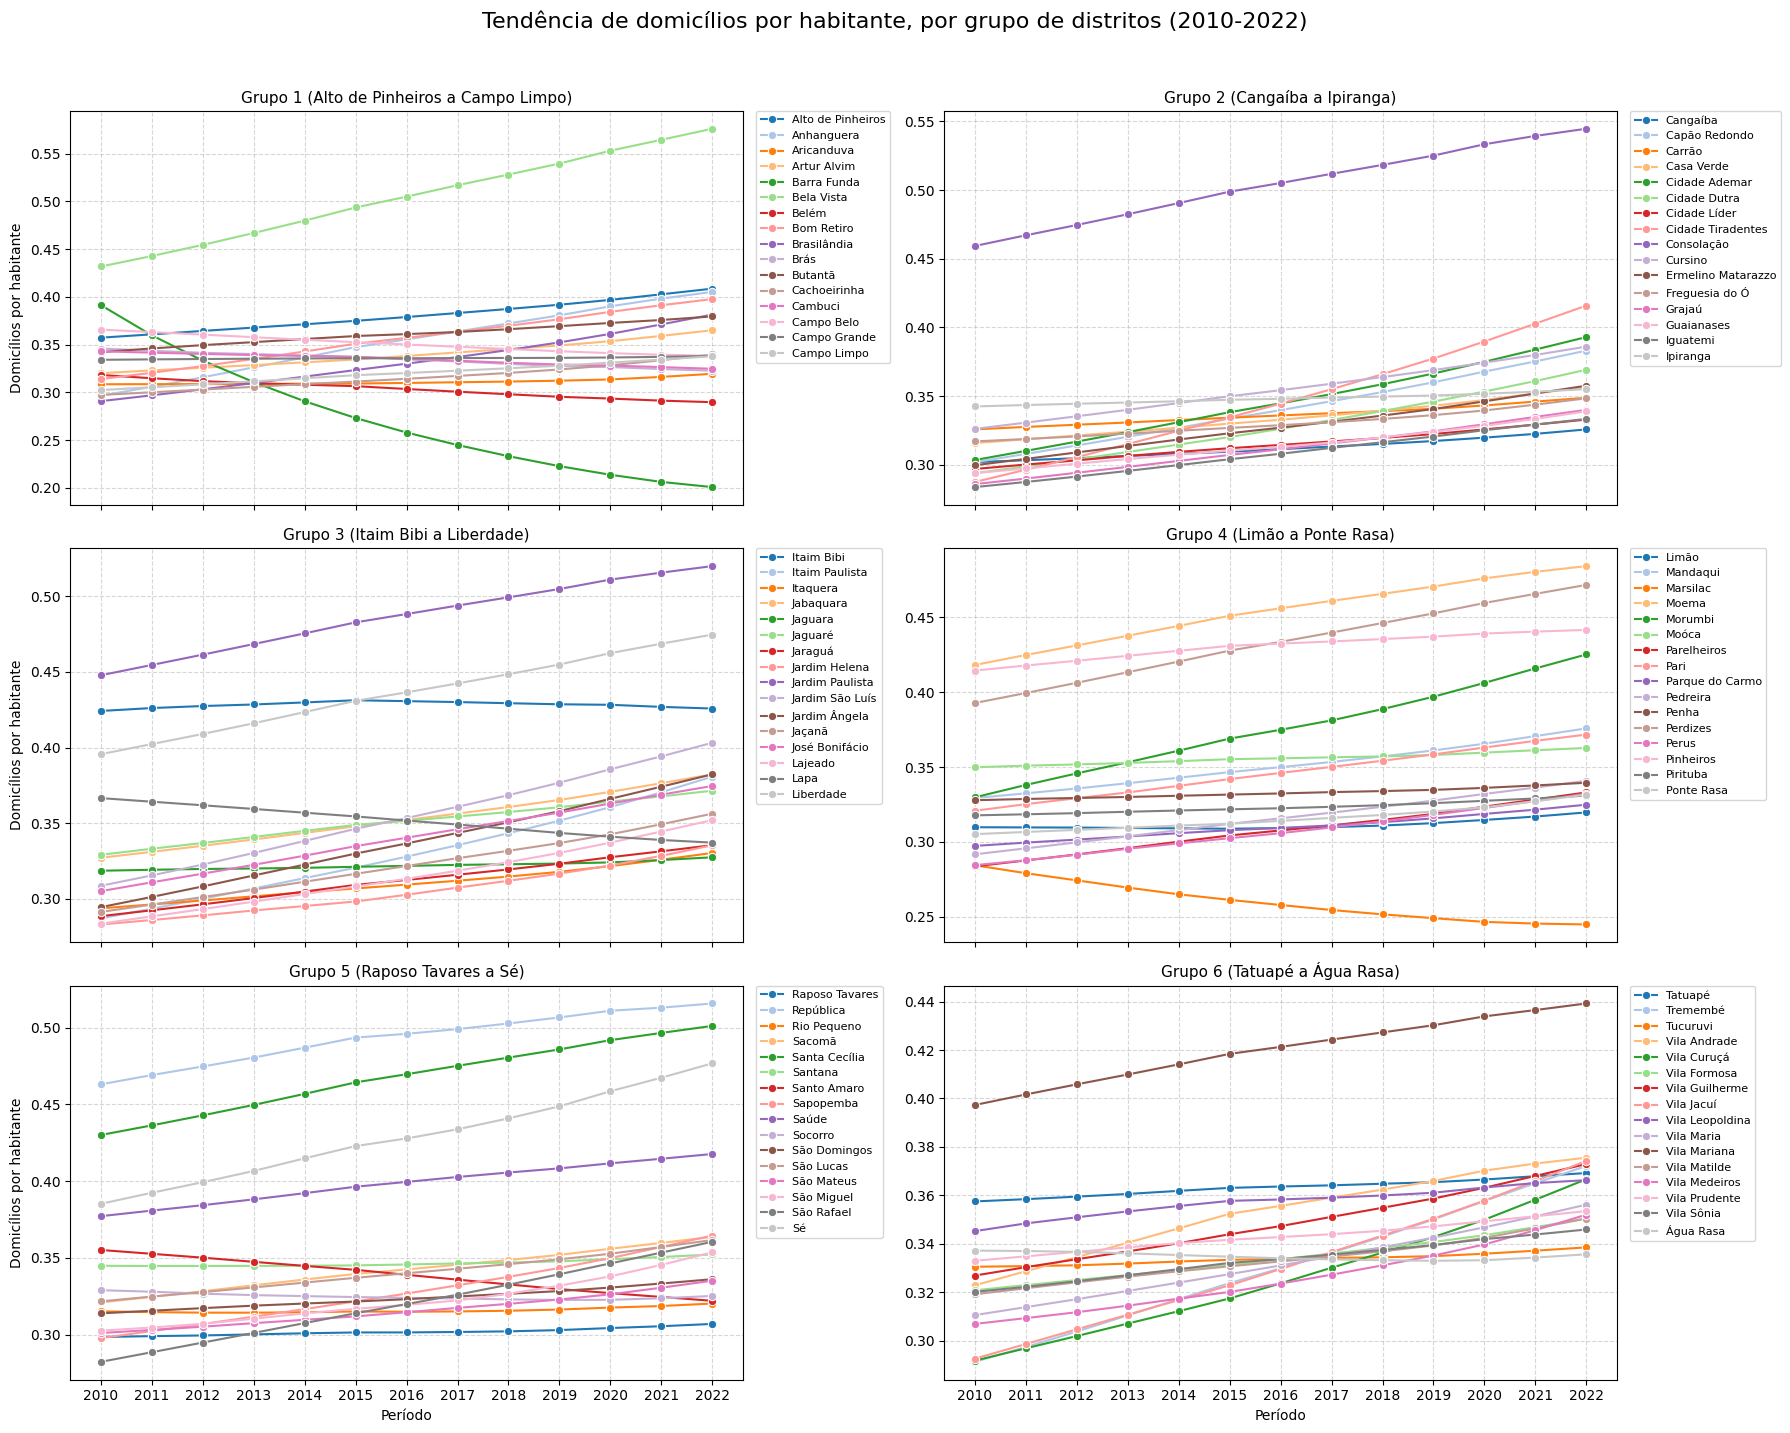

In [21]:
VAR_DOMICILIOS = "Domicílios Particulares Permanentes (por habitante)"

# A variável só tem dados até 2022; esta tendência fundamenta a projeção de 2023
df_plot = df[df["Período"].between(2010, 2022)].dropna(subset=[VAR_DOMICILIOS])
distritos = sorted(df_plot["Distrito"].unique())
grupos = [distritos[i:i + 16] for i in range(0, len(distritos), 16)]

fig, axes = plt.subplots(3, 2, figsize=(18, 14), sharex=True)
for i, (ax, grupo) in enumerate(zip(axes.flat, grupos)):
    sns.lineplot(
        data=df_plot[df_plot["Distrito"].isin(grupo)],
        x="Período", y=VAR_DOMICILIOS, hue="Distrito", marker="o", ax=ax, palette="tab20",
    )
    ax.set_title(f"Grupo {i + 1} ({grupo[0]} a {grupo[-1]})", fontsize=11)
    ax.set_ylabel("Domicílios por habitante" if i % 2 == 0 else "")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.0)

plt.xticks(range(2010, 2023))
fig.suptitle("Tendência de domicílios por habitante, por grupo de distritos (2010-2022)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Completude na janela candidata (2019–2023)

O ano de 2019 é descartado: três variáveis não têm dados nele (ver heatmap).

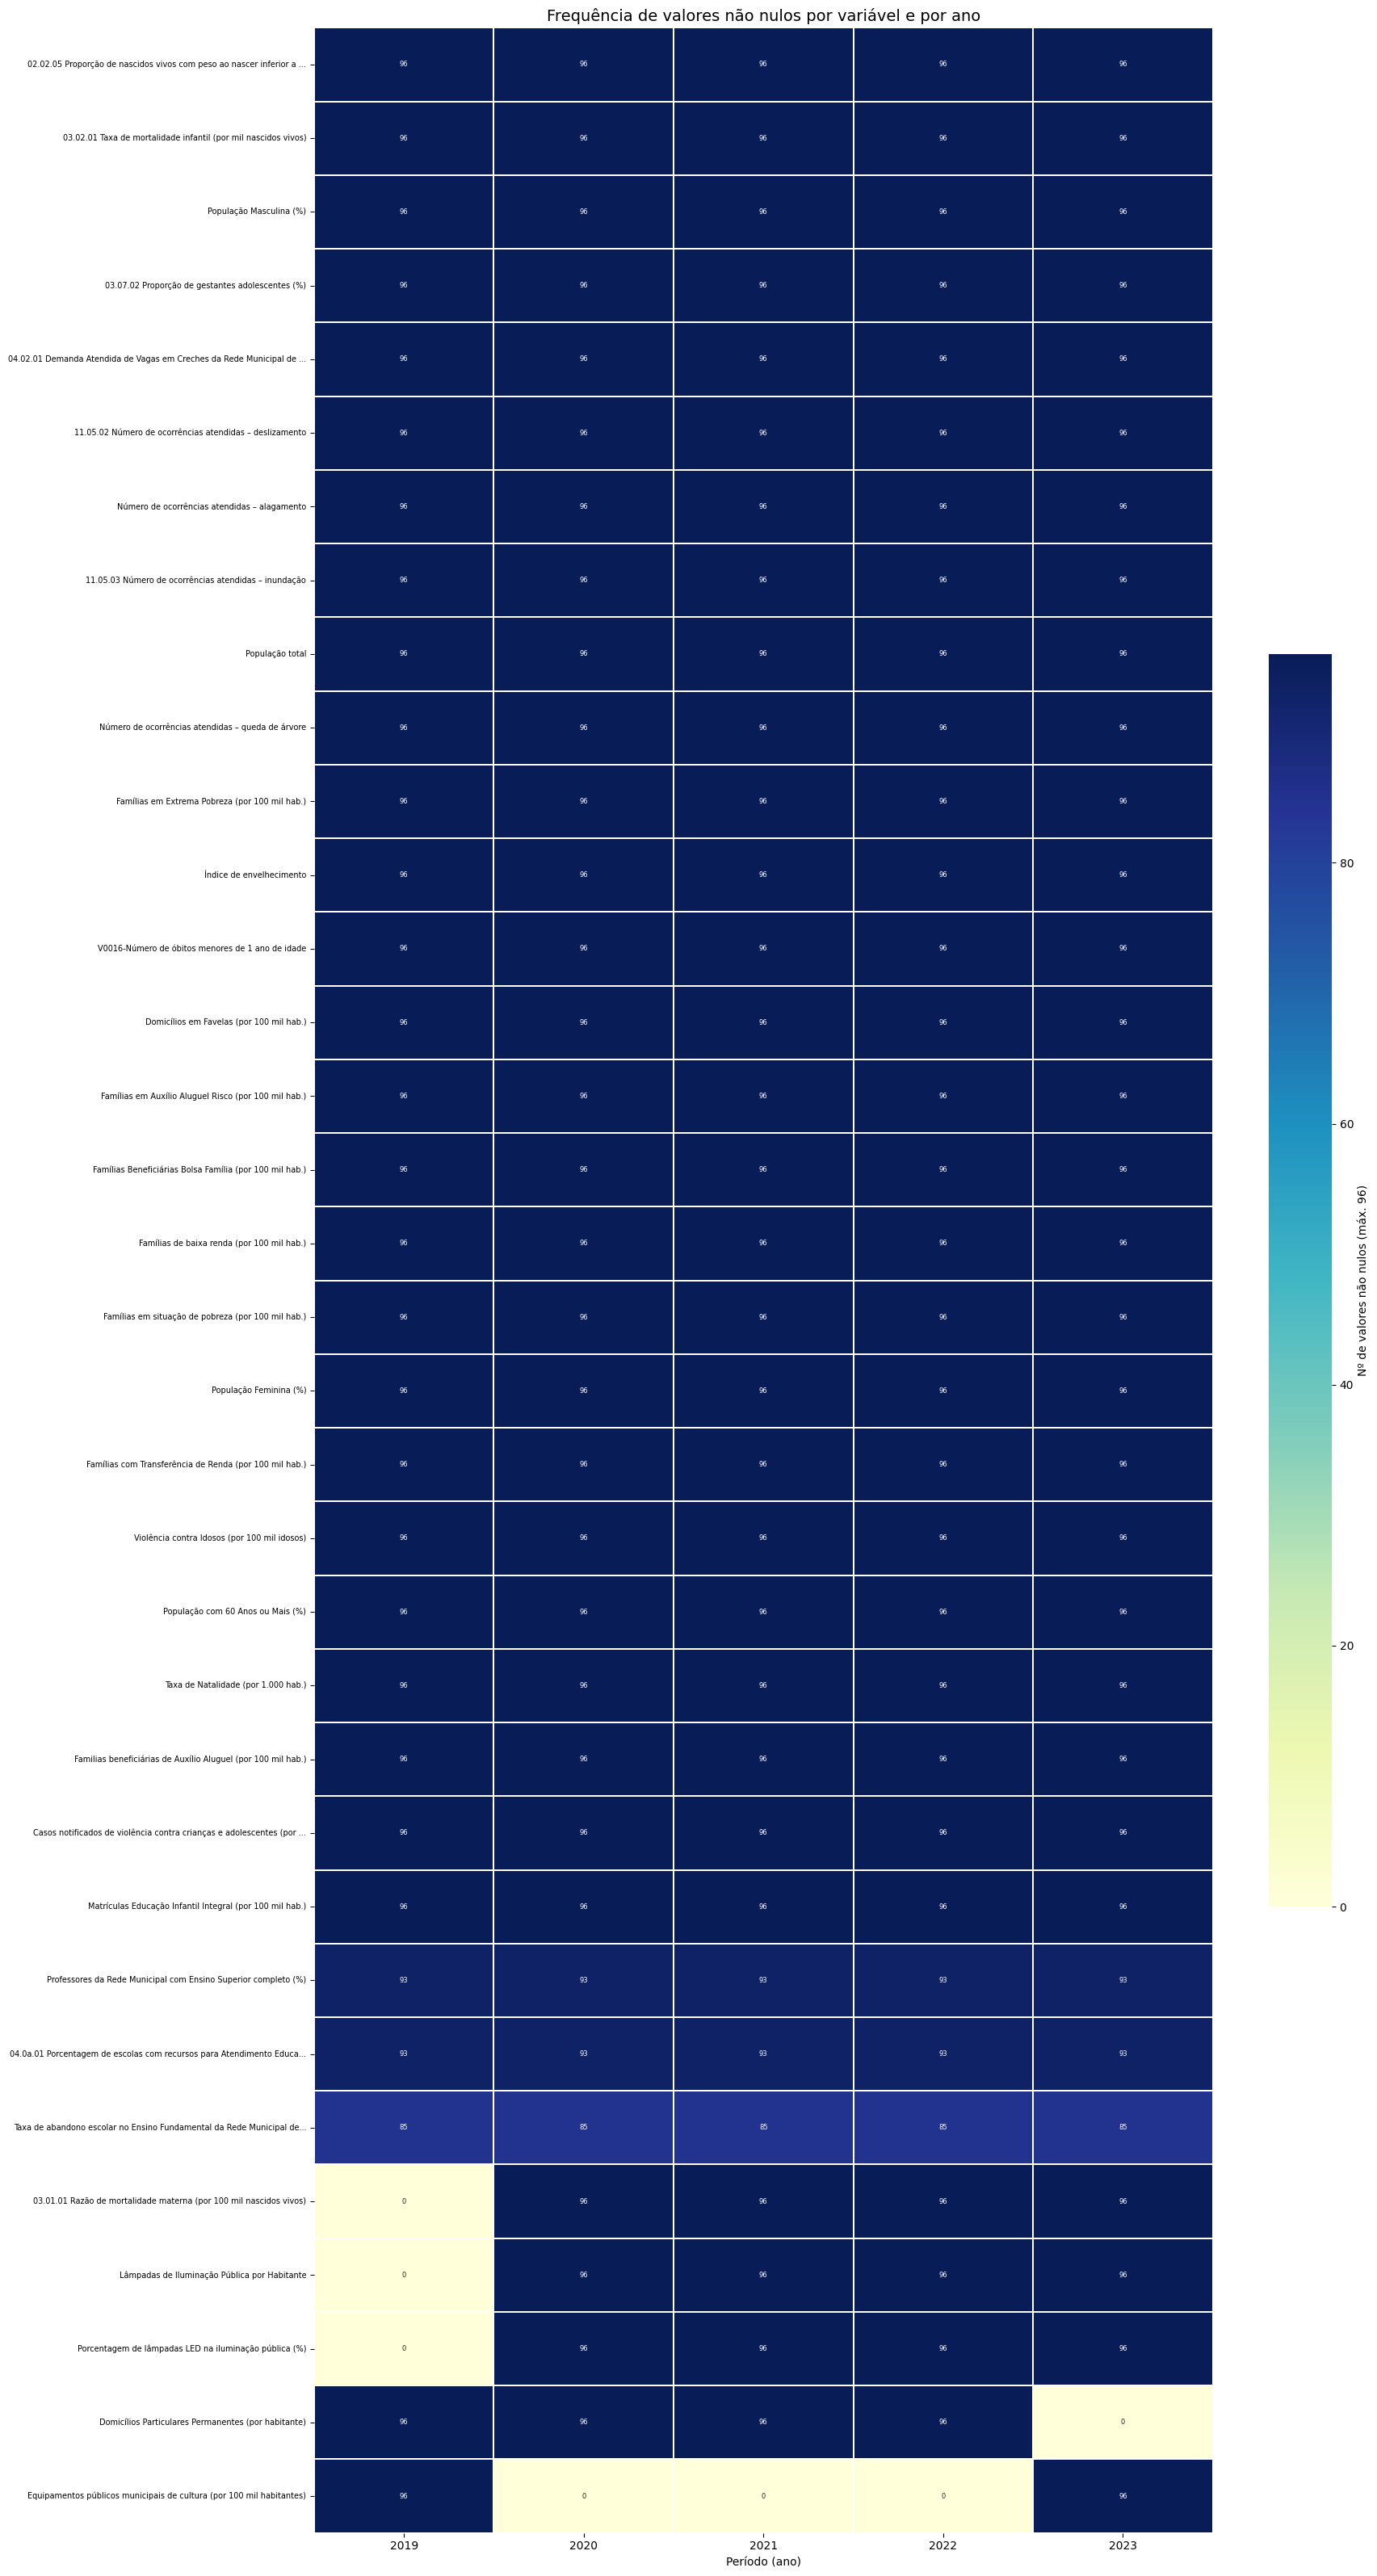

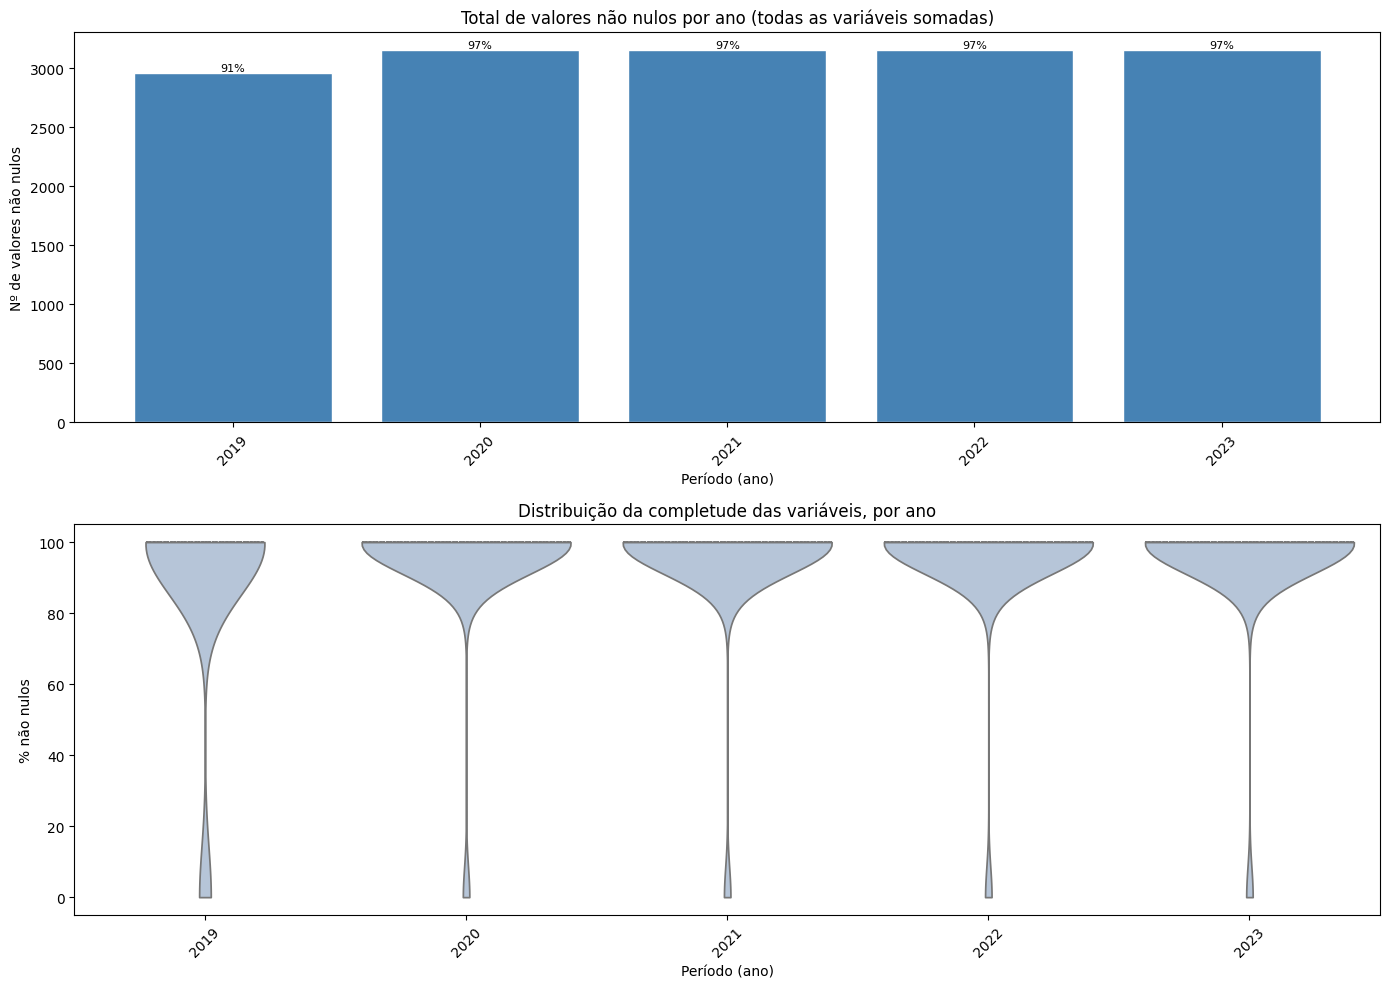

In [22]:
COLS_IDENTIFICACAO = ["Período", "Distrito"]


def plotar_completude(dados, arquivo=None):
    """Plota a completude (valores não nulos) por variável e por ano; salva o heatmap em `arquivo`, se informado."""
    variaveis = [c for c in dados.columns if c not in COLS_IDENTIFICACAO]
    tuplas_por_ano = dados.groupby("Período").size()  # distritos por ano

    freq = dados.groupby("Período")[variaveis].count().T  # linhas: variáveis; colunas: anos
    pct = freq.div(tuplas_por_ano, axis=1) * 100
    ordem = freq.sum(axis=1).sort_values(ascending=False).index
    freq, pct = freq.loc[ordem], pct.loc[ordem]

    # Rótulos truncados para caber no gráfico
    freq.index = [v if len(v) <= 70 else v[:67] + "..." for v in freq.index]
    pct.index = freq.index

    fig, ax = plt.subplots(figsize=(18, 32))
    sns.heatmap(
        freq, cmap="YlGnBu", annot=True, fmt="d", annot_kws={"size": 6}, linewidths=0.3, linecolor="white",
        cbar_kws={"label": f"Nº de valores não nulos (máx. {tuplas_por_ano.max()})", "shrink": 0.5}, ax=ax,
    )
    ax.set_title("Frequência de valores não nulos por variável e por ano", fontsize=14)
    ax.set_xlabel("Período (ano)")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=7)
    plt.tight_layout()
    if arquivo is not None:
        plt.savefig(arquivo, dpi=150)
    plt.show()

    total_por_ano = freq.sum()
    pct_total_por_ano = total_por_ano / (tuplas_por_ano * len(variaveis)) * 100

    fig, axes = plt.subplots(2, 1, figsize=(14, 10))

    axes[0].bar(total_por_ano.index, total_por_ano.values, color="steelblue", edgecolor="white")
    axes[0].set_xticks(total_por_ano.index)
    axes[0].set_xticklabels(total_por_ano.index, rotation=45)
    axes[0].set_title("Total de valores não nulos por ano (todas as variáveis somadas)")
    axes[0].set_xlabel("Período (ano)")
    axes[0].set_ylabel("Nº de valores não nulos")
    for ano, n, p in zip(total_por_ano.index, total_por_ano.values, pct_total_por_ano.values):
        axes[0].text(ano, n, f"{p:.0f}%", ha="center", va="bottom", fontsize=8)

    pct_long = pct.reset_index(drop=True).melt(var_name="ano", value_name="% não nulos")
    sns.violinplot(data=pct_long, x="ano", y="% não nulos", inner="quartile", cut=0, color="lightsteelblue", ax=axes[1])
    axes[1].set_title("Distribuição da completude das variáveis, por ano")
    axes[1].set_xlabel("Período (ano)")
    axes[1].tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()


df_candidato = df[df["Período"].between(2019, 2023)]
plotar_completude(df_candidato, PASTA_FIGURAS / "heatmap_frequencia_por_ano_pre_imputacao.png")

### Imputação na janela final (2020–2023)

In [23]:
df_sel = df[df["Período"].between(2020, 2023)].copy()

# 75% de nulos na janela (sem dados em 2020-2022)
df_sel = df_sel.drop(columns="Equipamentos públicos municipais de cultura (por 100 mil habitantes)")

# Lacunas espaciais: KNN (k=5, ponderado pela distância) sobre as três variáveis
variaveis_knn = [
    "04.0a.01 Porcentagem de escolas com recursos para Atendimento Educacional Especializado (%)",
    "Professores da Rede Municipal com Ensino Superior completo (%)",
    "Taxa de abandono escolar no Ensino Fundamental da Rede Municipal de Ensino (%)",
]
imputer = KNNImputer(n_neighbors=5, weights="distance")
df_sel[variaveis_knn] = imputer.fit_transform(df_sel[variaveis_knn])

# Lacuna temporal: projeta 2023 pela tendência linear do histórico 2010-2022 de cada distrito
historico = df[df["Período"].between(2010, 2022)]
for distrito, hist in historico.groupby("Distrito"):
    hist = hist.dropna(subset=[VAR_DOMICILIOS])
    if len(hist) < 2:
        continue
    coef = np.polyfit(hist["Período"], hist[VAR_DOMICILIOS], deg=1)
    linhas_2023 = (df_sel["Distrito"] == distrito) & (df_sel["Período"] == 2023)
    df_sel.loc[linhas_2023, VAR_DOMICILIOS] = np.polyval(coef, 2023)

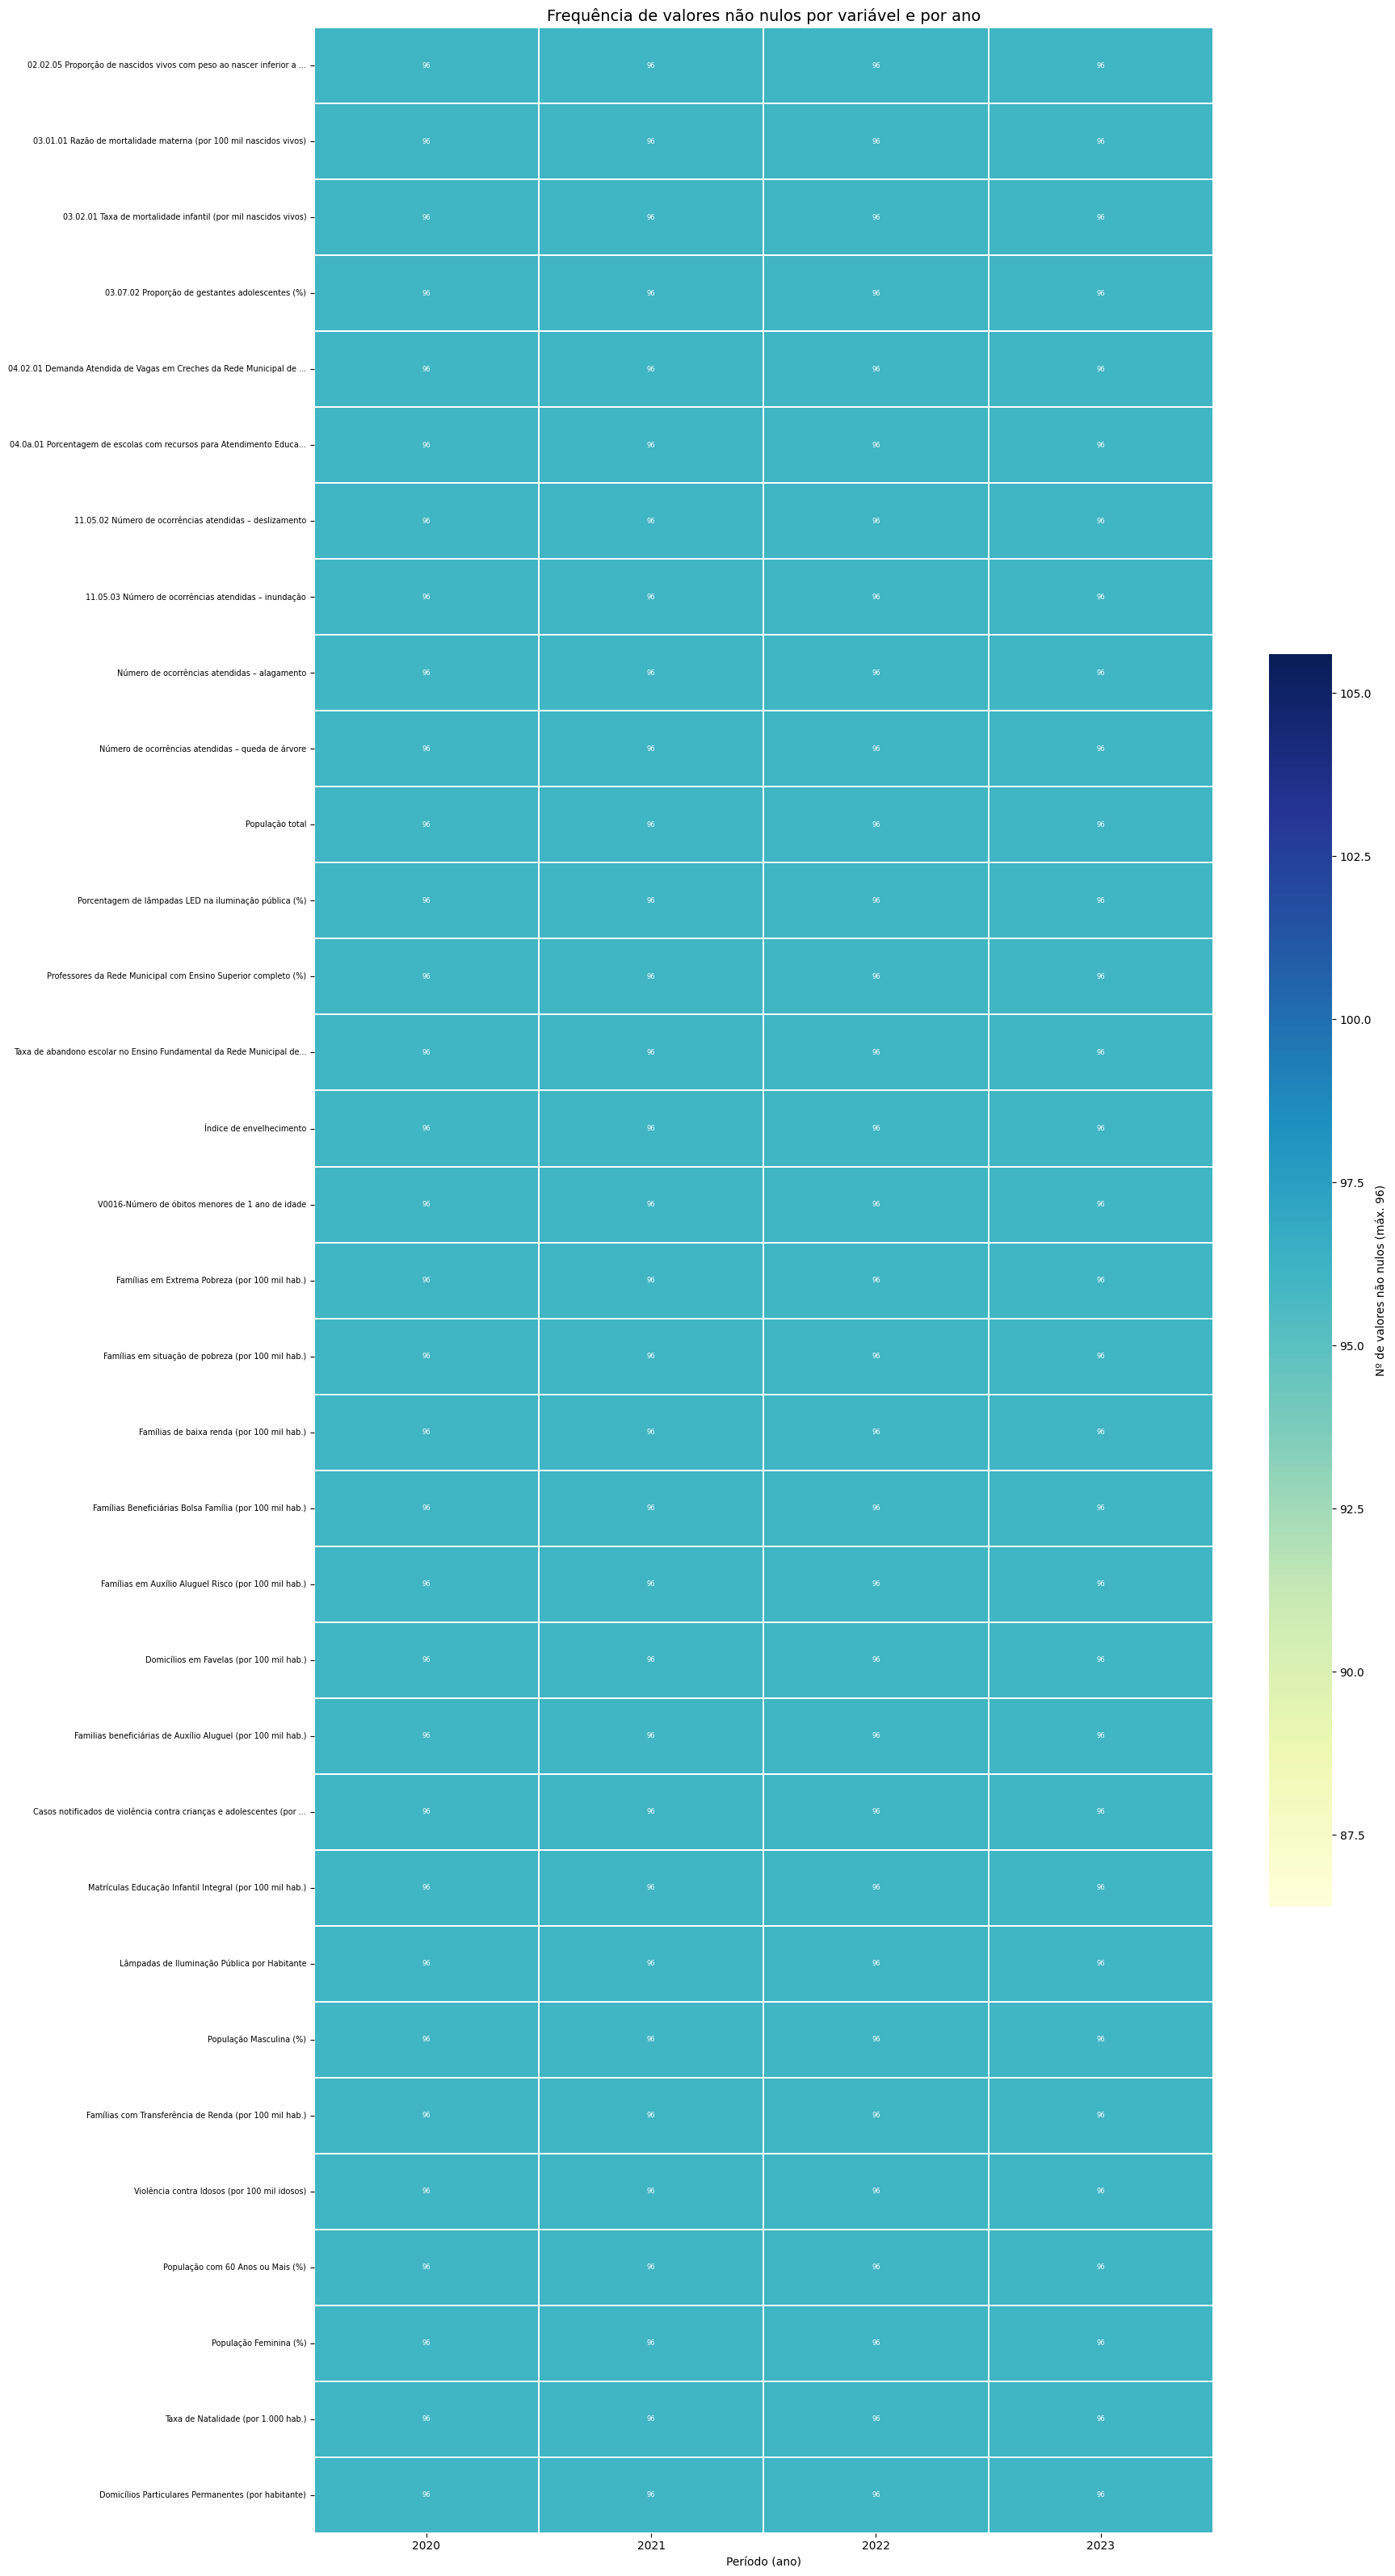

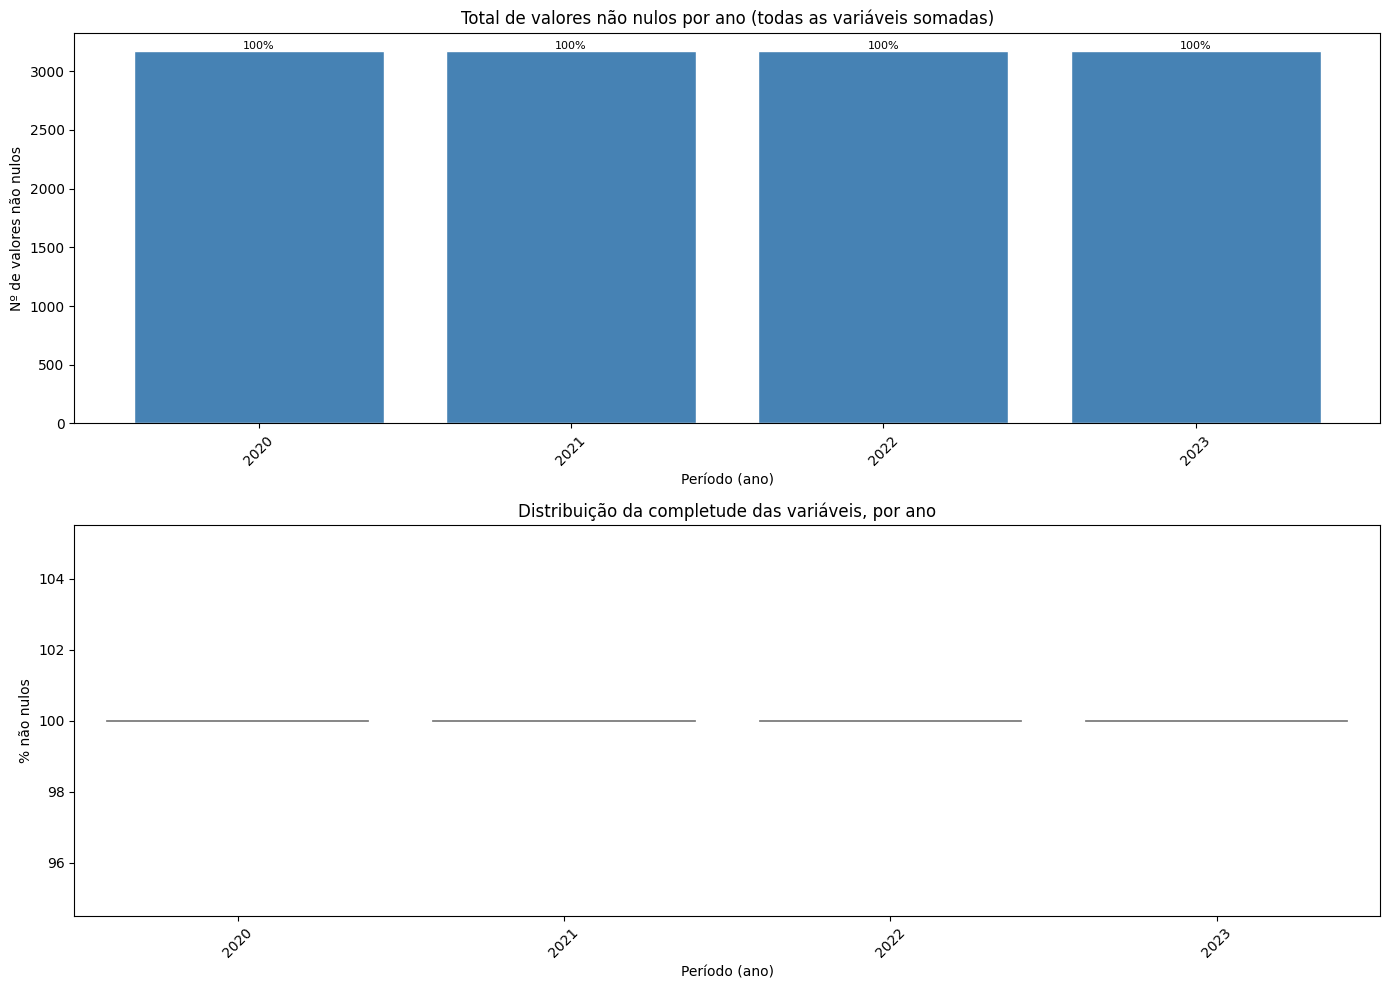

In [24]:
plotar_completude(df_sel, PASTA_FIGURAS / "heatmap_frequencia_por_ano_pos_imputacao.png")
assert df_sel.isnull().sum().sum() == 0, "Ainda há valores nulos após a imputação."

## Pooling

Os anos da janela são empilhados: cada linha representa um par distrito-ano.

In [25]:
df_pooled = df_sel.sort_values(["Distrito", "Período"]).reset_index(drop=True)
df_pooled.head()

,Período,Distrito,02.02.05 Proporção de nascidos vivos com peso ao nascer inferior a 2.500 gramas (%),03.01.01 Razão de mortalidade materna (por 100 mil nascidos vivos),03.02.01 Taxa de mortalidade infantil (por mil nascidos vivos),03.07.02 Proporção de gestantes adolescentes (%),04.02.01 Demanda Atendida de Vagas em Creches da Rede Municipal de Ensino (%),04.0a.01 Porcentagem de escolas com recursos para Atendimento Educacional Especializado (%),11.05.02 Número de ocorrências atendidas – deslizamento,11.05.03 Número de ocorrências atendidas – inundação,...,Casos notificados de violência contra crianças e adolescentes (por 100 mil hab.),Matrículas Educação Infantil Integral (por 100 mil hab.),Lâmpadas de Iluminação Pública por Habitante,População Masculina (%),Famílias com Transferência de Renda (por 100 mil hab.),Violência contra Idosos (por 100 mil idosos),População com 60 Anos ou Mais (%),População Feminina (%),Taxa de Natalidade (por 1.000 hab.),Domicílios Particulares Permanentes (por habitante)
0,2020,Alto de Pinheiros,7.6125,0.0000,0.0000,1.3841,100.0000,19.761565,1.0,0.0,...,15.269118,0.000000,0.119048,44.868304,246.850744,16.937669,30.049625,55.131696,7.354625,0.396793
1,2021,Alto de Pinheiros,9.1255,0.0000,15.2091,1.1407,100.0000,19.761565,0.0,0.0,...,28.441411,0.000000,0.097761,44.841762,263.729445,33.528919,30.846003,55.158238,6.800083,0.402653
2,2022,Alto de Pinheiros,5.6522,0.0000,4.3478,0.0000,100.0000,19.761565,0.0,0.0,...,15.761269,0.000000,0.130214,44.811916,370.389829,74.744623,31.630241,55.188084,6.041820,0.408558
3,2023,Alto de Pinheiros,12.7820,0.0000,3.7594,0.0000,100.0000,19.761565,0.0,1.0,...,7.993179,0.000000,0.135351,44.780454,455.611212,41.074509,32.433657,55.219546,7.087286,0.409604
4,2020,Anhanguera,9.1762,104.2753,11.4703,10.1147,99.7469,9.090900,14.0,1.0,...,50.232154,491.460534,0.059600,48.734693,7701.811073,61.040745,8.896522,51.265307,13.019631,0.390073


## Ajuste de monotonicidade

In [26]:
# Variáveis em que valores maiores indicam pior qualidade de vida
var_negativas = [
    "02.02.05 Proporção de nascidos vivos com peso ao nascer inferior a 2.500 gramas (%)",
    "03.01.01 Razão de mortalidade materna (por 100 mil nascidos vivos)",
    "03.02.01 Taxa de mortalidade infantil (por mil nascidos vivos)",
    "03.07.02 Proporção de gestantes adolescentes (%)",
    "11.05.02 Número de ocorrências atendidas – deslizamento",
    "11.05.03 Número de ocorrências atendidas – inundação",
    "Número de ocorrências atendidas – alagamento",
    "Número de ocorrências atendidas – queda de árvore",
    "Taxa de abandono escolar no Ensino Fundamental da Rede Municipal de Ensino (%)",
    "V0016-Número de óbitos menores de 1 ano de idade",
    "Famílias em Extrema Pobreza (por 100 mil hab.)",
    "Famílias em situação de pobreza (por 100 mil hab.)",
    "Famílias de baixa renda (por 100 mil hab.)",
    "Famílias Beneficiárias Bolsa Família (por 100 mil hab.)",
    "Famílias em Auxílio Aluguel Risco (por 100 mil hab.)",
    "Domicílios em Favelas (por 100 mil hab.)",
    "Familias beneficiárias de Auxílio Aluguel (por 100 mil hab.)",
    "Casos notificados de violência contra crianças e adolescentes (por 100 mil hab.)",
    "Famílias com Transferência de Renda (por 100 mil hab.)",
    "Violência contra Idosos (por 100 mil idosos)",
]

# Inverte o sinal para que todas as variáveis cresçam com a qualidade de vida
df_adj = df_pooled.copy()
df_adj[var_negativas] = -df_adj[var_negativas]

## Normalização

Padronização das variáveis. A função aceita `'standard'` (z-score) ou `'minmax'`; o modelo usa `'standard'`.

In [27]:
def escalonar_indicadores(df, colunas, metodo="minmax"):
    """Escalona `colunas` por Min-Max ('minmax') ou z-score ('standard')."""
    metodo = metodo.lower().strip()
    if metodo == "minmax":
        scaler = MinMaxScaler()
    elif metodo in ("standard", "zscore", "z-score"):
        scaler = StandardScaler()
    else:
        raise ValueError("Método inválido: escolha entre 'minmax' ou 'standard'.")

    df_scaled = df.copy()
    df_scaled[colunas] = scaler.fit_transform(df_scaled[colunas])
    return df_scaled


colunas_ignorar = ["Período", "Distrito"]
todas_var_qol = [c for c in df_adj.columns if c not in colunas_ignorar]
df_standard = escalonar_indicadores(df_adj, colunas=todas_var_qol, metodo="standard")

## Análise fatorial

### Seleção das variáveis

In [28]:
# Excluídas: identificadores, demografia pura (população total; % masculina e feminina, com r = -1,0),
# indicadores de renda redundantes (r > 0,85) ou limitados por cota (Bolsa Família) e iluminação pública.
# Mantém-se apenas 'Famílias em situação de pobreza' como proxy de renda.
colunas_excluir = [
    "Período",
    "Distrito",
    "População total",
    "População Masculina (%)",
    "População Feminina (%)",
    "Famílias em Extrema Pobreza (por 100 mil hab.)",
    "Famílias de baixa renda (por 100 mil hab.)",
    "Famílias Beneficiárias Bolsa Família (por 100 mil hab.)",
    "Famílias com Transferência de Renda (por 100 mil hab.)",
    "Lâmpadas de Iluminação Pública por Habitante",
]

var_qol_puras = [c for c in df_standard.columns if c not in colunas_excluir]
X_qol_scaled = df_standard[var_qol_puras].values

print(f"Variáveis selecionadas: {len(var_qol_puras)}")

Variáveis selecionadas: 25


### Adequação dos dados (KMO e Bartlett)

In [29]:
def bartlett_esfericidade(X):
    """Teste de esfericidade de Bartlett: retorna a estatística qui-quadrado e o p-valor."""
    n, p = X.shape
    _, log_det = np.linalg.slogdet(np.corrcoef(X, rowvar=False))
    estatistica = -(n - 1 - (2 * p + 5) / 6) * log_det
    return estatistica, chi2_dist.sf(estatistica, p * (p - 1) / 2)


def kmo(X):
    """Medida de Kaiser-Meyer-Olkin: retorna o KMO por variável e o KMO total."""
    corr = np.corrcoef(X, rowvar=False)
    inv = np.linalg.pinv(corr)
    d = np.sqrt(np.outer(np.diag(inv), np.diag(inv)))
    parcial = -inv / d  # correlações parciais
    np.fill_diagonal(corr, 0)
    np.fill_diagonal(parcial, 0)
    r2, p2 = (corr ** 2).sum(axis=0), (parcial ** 2).sum(axis=0)
    return r2 / (r2 + p2), r2.sum() / (r2.sum() + p2.sum())


chi2, p = bartlett_esfericidade(X_qol_scaled)
kmo_por_variavel, kmo_total = kmo(X_qol_scaled)
print(f"KMO = {kmo_total:.2f} | Bartlett chi2 = {chi2:.1f} | p = {p:.3g}")

KMO = 0.80 | Bartlett chi2 = 5732.7 | p = 0


### Número de fatores (critério de Kaiser e scree plot)

Critério de Kaiser: 8 fatores com autovalor > 1,0
   Fator  Autovalor  % Variância Individual  % Variância Acumulada
 Fator 1      7.270                   29.01                  29.01
 Fator 2      2.090                    8.34                  37.35
 Fator 3      1.732                    6.91                  44.26
 Fator 4      1.583                    6.31                  50.57
 Fator 5      1.239                    4.94                  55.51
 Fator 6      1.185                    4.73                  60.24
 Fator 7      1.110                    4.43                  64.67
 Fator 8      1.022                    4.08                  68.75
 Fator 9      0.963                    3.84                  72.59
Fator 10      0.897                    3.58                  76.17


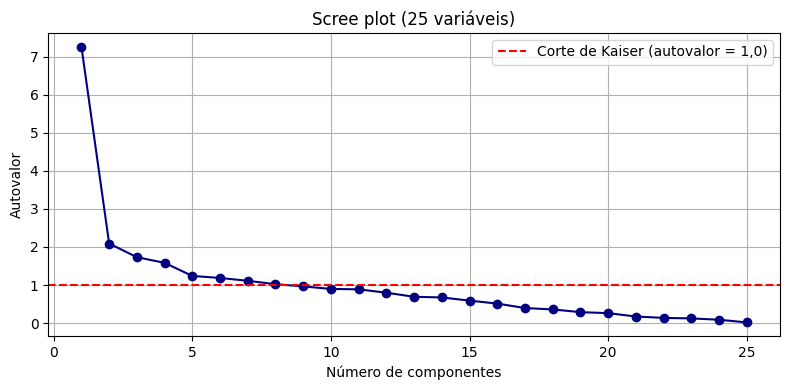

In [30]:
pca_diag = PCA().fit(X_qol_scaled)
autovalores = pca_diag.explained_variance_
var_acumulada = np.cumsum(pca_diag.explained_variance_ratio_)
n_kaiser = int(np.sum(autovalores > 1.0))

df_diag = pd.DataFrame({
    "Fator": [f"Fator {i + 1}" for i in range(len(autovalores))],
    "Autovalor": np.round(autovalores, 3),
    "% Variância Individual": np.round(pca_diag.explained_variance_ratio_ * 100, 2),
    "% Variância Acumulada": np.round(var_acumulada * 100, 2),
})

print(f"Critério de Kaiser: {n_kaiser} fatores com autovalor > 1,0")
print(df_diag.head(10).to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(autovalores) + 1), autovalores, "o-", color="navy")
plt.axhline(y=1, color="red", linestyle="--", label="Corte de Kaiser (autovalor = 1,0)")
plt.title(f"Scree plot ({len(var_qol_puras)} variáveis)")
plt.xlabel("Número de componentes")
plt.ylabel("Autovalor")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Rotação Varimax

In [31]:
LIMITE_CARGA = 0.40  # carga mínima para uma variável definir o fator

for k_test in [5, 6, 7, 8]:
    fa_test = FactorAnalysis(n_components=k_test, rotation="varimax", random_state=42).fit(X_qol_scaled)
    cargas = pd.DataFrame(
        fa_test.components_.T, index=var_qol_puras, columns=[f"Fator_{i + 1}" for i in range(k_test)]
    )

    print("=" * 50)
    print(f"TESTE COM {k_test} FATORES (VARIMAX)")
    print("=" * 50)

    fatores_validos = 0
    for col in cargas.columns:
        var_chaves = cargas[col][cargas[col].abs() >= LIMITE_CARGA].sort_values(ascending=False)
        qtd = len(var_chaves)
        status = "OK (robusto)" if qtd >= 2 else "ALERTA (fraco/solitário)"
        fatores_validos += qtd >= 2

        print(f">>> {col} [{status}] -> {qtd} variáveis com carga >= {LIMITE_CARGA:.2f}:")
        print(var_chaves.round(3).to_string() if qtd else "   [Nenhuma variável com carga acima do limite]")
        print("-" * 50)

    print(f"RESUMO {k_test} FATORES: {fatores_validos} de {k_test} são robustos (>= 2 variáveis).\n")

TESTE COM 5 FATORES (VARIMAX)
>>> Fator_1 [OK (robusto)] -> 11 variáveis com carga >= 0.40:
Índice de envelhecimento                                                            0.978
População com 60 Anos ou Mais (%)                                                   0.964
03.07.02 Proporção de gestantes adolescentes (%)                                    0.889
Famílias em situação de pobreza (por 100 mil hab.)                                  0.791
V0016-Número de óbitos menores de 1 ano de idade                                    0.638
Domicílios em Favelas (por 100 mil hab.)                                            0.516
03.02.01 Taxa de mortalidade infantil (por mil nascidos vivos)                      0.513
Casos notificados de violência contra crianças e adolescentes (por 100 mil hab.)    0.471
Violência contra Idosos (por 100 mil idosos)                                        0.410
Matrículas Educação Infantil Integral (por 100 mil hab.)                           -0.414
Taxa de 

TESTE COM 6 FATORES (VARIMAX)
>>> Fator_1 [OK (robusto)] -> 11 variáveis com carga >= 0.40:
Índice de envelhecimento                                                            0.979
População com 60 Anos ou Mais (%)                                                   0.967
03.07.02 Proporção de gestantes adolescentes (%)                                    0.888
Famílias em situação de pobreza (por 100 mil hab.)                                  0.797
V0016-Número de óbitos menores de 1 ano de idade                                    0.685
Domicílios em Favelas (por 100 mil hab.)                                            0.559
03.02.01 Taxa de mortalidade infantil (por mil nascidos vivos)                      0.519
Casos notificados de violência contra crianças e adolescentes (por 100 mil hab.)    0.481
Violência contra Idosos (por 100 mil idosos)                                        0.414
Matrículas Educação Infantil Integral (por 100 mil hab.)                           -0.426
Taxa de 

### Extração dos escores fatoriais

In [32]:
n_fatores_final = 5

fa_final = FactorAnalysis(n_components=n_fatores_final, rotation="varimax", random_state=42)
scores_fatores = fa_final.fit_transform(X_qol_scaled)

# Nomes atribuídos após interpretar as cargas fatoriais; revise-os se os dados ou a versão do scikit-learn mudarem
nomes_pilares = [
    "Fator_1_Alto_Desenvolvimento_Socioeconômico",
    "Fator_2_Vulnerabilidade_Habitacional",
    "Fator_3_Violência_contra_Dependentes",
    "Fator_4_Mortalidade_Infantil_e_Submoradia",
    "Fator_5_Risco_Hidrológico",
]

df_fatores = pd.DataFrame(scores_fatores, columns=nomes_pilares, index=df_standard.index)

# Preserva Período e Distrito para identificar os pontos após a clusterização
df_fatores_final = pd.concat([df_standard[["Período", "Distrito"]], df_fatores], axis=1)
df_fatores_final.head()

,Período,Distrito,Fator_1_Alto_Desenvolvimento_Socioeconômico,Fator_2_Vulnerabilidade_Habitacional,Fator_3_Violência_contra_Dependentes,Fator_4_Mortalidade_Infantil_e_Submoradia,Fator_5_Risco_Hidrológico
0,2020,Alto de Pinheiros,2.330452,-0.324354,0.001272,0.428509,0.069868
1,2021,Alto de Pinheiros,2.568622,-0.317550,0.343661,1.084634,-0.083687
2,2022,Alto de Pinheiros,2.885625,-0.235941,0.732276,0.862467,0.072185
3,2023,Alto de Pinheiros,3.080818,-0.231109,0.585378,1.345562,0.188849
4,2020,Anhanguera,-1.747674,-0.698400,-1.345697,-1.090957,-0.504749


## Treinamento do modelo

### Grid Search

Configurações testadas (da melhor para a pior)

  Algoritmo               Hiperparâmetros  K  WCSS (Inércia)  Silhueta (↑)  Davies-Bouldin (↓)  CH (↑)
Hierárquico  link=average, dist=manhattan  2             NaN         0.665               0.335  26.829
Hierárquico   link=single, dist=euclidean  2             NaN         0.665               0.335  26.829
Hierárquico   link=single, dist=manhattan  2             NaN         0.665               0.335  26.829
Hierárquico   link=single, dist=euclidean  3             NaN         0.587               0.364  33.250
Hierárquico   link=single, dist=manhattan  3             NaN         0.587               0.364  33.250
Hierárquico   link=single, dist=euclidean  4             NaN         0.576               0.374  31.971
Hierárquico  link=average, dist=euclidean  2             NaN         0.559               0.568  42.853
Hierárquico  link=average, dist=euclidean  3             NaN         0.526               0.661  44.791
Hierárquico  link=average

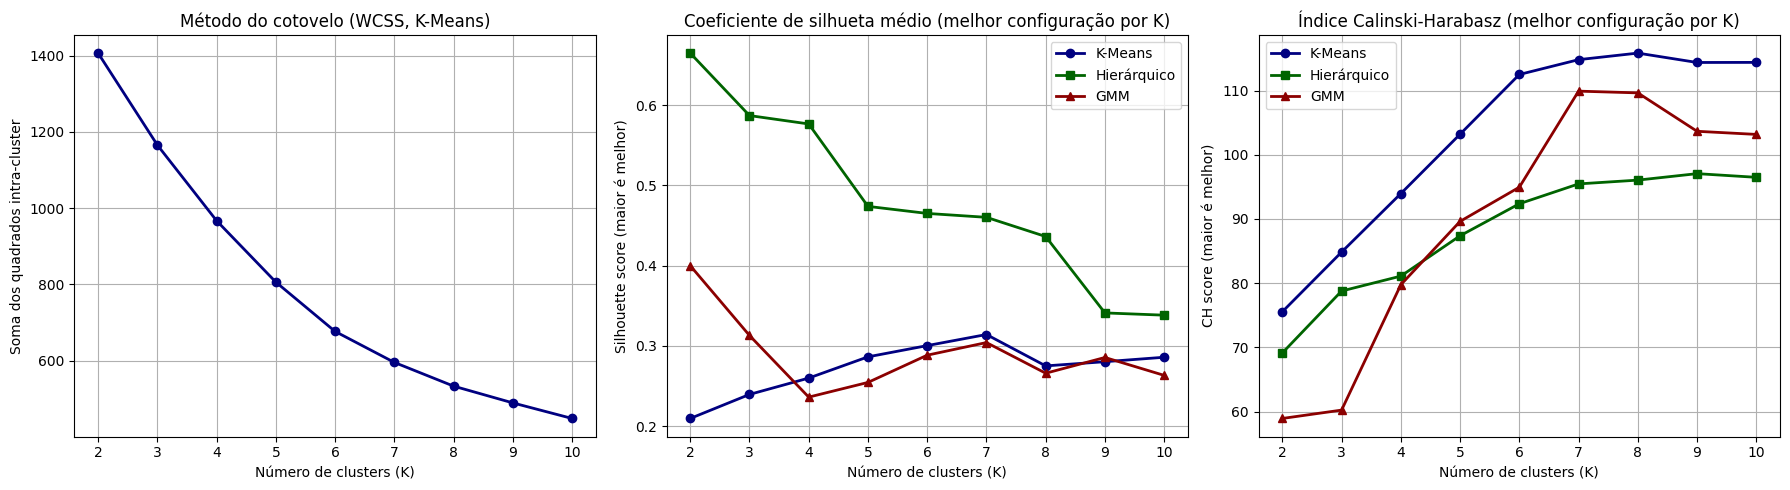

In [33]:
X = df_fatores.values
k_range = range(2, 11)
resultados = []


def registrar(algoritmo, hiperparametros, k, labels, wcss=np.nan):
    resultados.append({
        "Algoritmo": algoritmo,
        "Hiperparâmetros": hiperparametros,
        "K": k,
        "WCSS (Inércia)": wcss,
        "Silhueta (↑)": silhouette_score(X, labels),
        "Davies-Bouldin (↓)": davies_bouldin_score(X, labels),
        "CH (↑)": calinski_harabasz_score(X, labels),
    })


linkage_metrics = [
    ("ward", "euclidean"),
    ("complete", "euclidean"), ("complete", "manhattan"), ("complete", "cosine"),
    ("average", "euclidean"), ("average", "manhattan"), ("average", "cosine"),
    ("single", "euclidean"), ("single", "manhattan"),
]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # avisos de convergência do GMM

    for k in k_range:
        for init_method in ["k-means++", "random"]:
            km = KMeans(n_clusters=k, init=init_method, n_init=30, max_iter=500, random_state=42)
            registrar("K-Means", f"init={init_method}", k, km.fit_predict(X), wcss=km.inertia_)

        for link, metric in linkage_metrics:
            agg = AgglomerativeClustering(n_clusters=k, linkage=link, metric=metric)
            registrar("Hierárquico", f"link={link}, dist={metric}", k, agg.fit_predict(X))

        for cov in ["full", "tied", "diag", "spherical"]:
            for init_param in ["kmeans", "random"]:
                gmm = GaussianMixture(
                    n_components=k, covariance_type=cov, init_params=init_param, n_init=5, random_state=42
                )
                registrar("GMM", f"cov={cov}, init={init_param}", k, gmm.fit_predict(X))

df_grid = pd.DataFrame(resultados)
df_grid_sorted = df_grid.sort_values(by=["Silhueta (↑)", "Davies-Bouldin (↓)"], ascending=[False, True])

print("Configurações testadas (da melhor para a pior)\n")
print(df_grid_sorted.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Cotovelo: apenas K-Means, que é o único com inércia
df_wcss = df_grid[df_grid["Algoritmo"] == "K-Means"].groupby("K")["WCSS (Inércia)"].min()
ax[0].plot(df_wcss.index, df_wcss.values, "o-", color="navy", linewidth=2)
ax[0].set_title("Método do cotovelo (WCSS, K-Means)", fontsize=12)
ax[0].set_xlabel("Número de clusters (K)")
ax[0].set_ylabel("Soma dos quadrados intra-cluster")
ax[0].grid(True)

# Silhueta e Calinski-Harabasz: melhor configuração de cada algoritmo para cada K
modelos = ["K-Means", "Hierárquico", "GMM"]
cores = ["navy", "darkgreen", "darkred"]
marcadores = ["o-", "s-", "^-"]

for modelo, cor_modelo, marcador in zip(modelos, cores, marcadores):
    df_modelo = df_grid[df_grid["Algoritmo"] == modelo]
    best_sil = df_modelo.groupby("K")["Silhueta (↑)"].max()
    best_ch = df_modelo.groupby("K")["CH (↑)"].max()
    ax[1].plot(best_sil.index, best_sil.values, marcador, color=cor_modelo, linewidth=2, label=modelo)
    ax[2].plot(best_ch.index, best_ch.values, marcador, color=cor_modelo, linewidth=2, label=modelo)

ax[1].set_title("Coeficiente de silhueta médio (melhor configuração por K)", fontsize=12)
ax[1].set_xlabel("Número de clusters (K)")
ax[1].set_ylabel("Silhouette score (maior é melhor)")
ax[1].legend()
ax[1].grid(True)

ax[2].set_title("Índice Calinski-Harabasz (melhor configuração por K)", fontsize=12)
ax[2].set_xlabel("Número de clusters (K)")
ax[2].set_ylabel("CH score (maior é melhor)")
ax[2].legend()
ax[2].grid(True)

plt.tight_layout()
plt.show()

### K-Means final e validação estatística

In [34]:
k_definitivo = 7

colunas_fatores = [c for c in df_fatores_final.columns if c.startswith("Fator_")]
X_final = df_fatores_final[colunas_fatores].values

kmeans = KMeans(n_clusters=k_definitivo, init="k-means++", n_init=30, random_state=42)

df_resultado = df_fatores_final.copy()
df_resultado["Cluster"] = kmeans.fit_predict(X_final)

print("Distritos-ano por cluster:")
print(df_resultado["Cluster"].value_counts().sort_index())


def anova_por_fator(df, fatores, coluna_cluster="Cluster"):
    """ANOVA de um fator: testa se a média de cada fator latente difere entre os clusters."""
    linhas = []
    for fator in fatores:
        grupos = [g[fator].values for _, g in df.groupby(coluna_cluster)]
        f_stat, p_val = f_oneway(*grupos)
        linhas.append({
            "Fator Latente": fator,
            "Estatística F": round(f_stat, 2),
            "p-valor": f"{p_val:.4e}",
            "Significância": "Significativo" if p_val < 0.05 else "Não Significativo",
        })
    return pd.DataFrame(linhas)


print("\nValidação estatística (ANOVA) - K-Means")
print(anova_por_fator(df_resultado, colunas_fatores).to_string(index=False))

Distritos-ano por cluster:
Cluster
0    101
1    148
2     60
3     13
4     12
5      6
6     44
Name: count, dtype: int64

Validação estatística (ANOVA) - K-Means
                              Fator Latente  Estatística F     p-valor Significância
Fator_1_Alto_Desenvolvimento_Socioeconômico         128.57  5.2919e-88 Significativo
       Fator_2_Vulnerabilidade_Habitacional         430.31 2.9646e-165 Significativo
       Fator_3_Violência_contra_Dependentes          86.48  8.4403e-68 Significativo
  Fator_4_Mortalidade_Infantil_e_Submoradia          59.65  9.7676e-52 Significativo
                  Fator_5_Risco_Hidrológico          83.85  2.3324e-66 Significativo


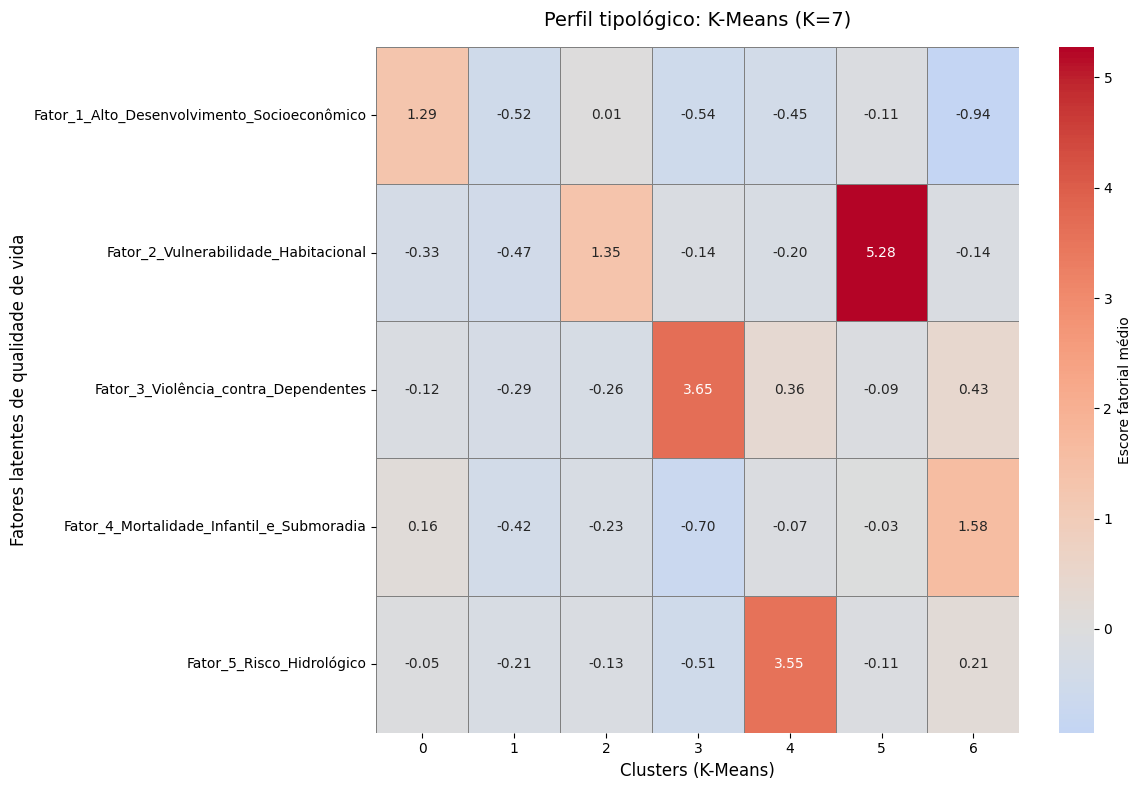

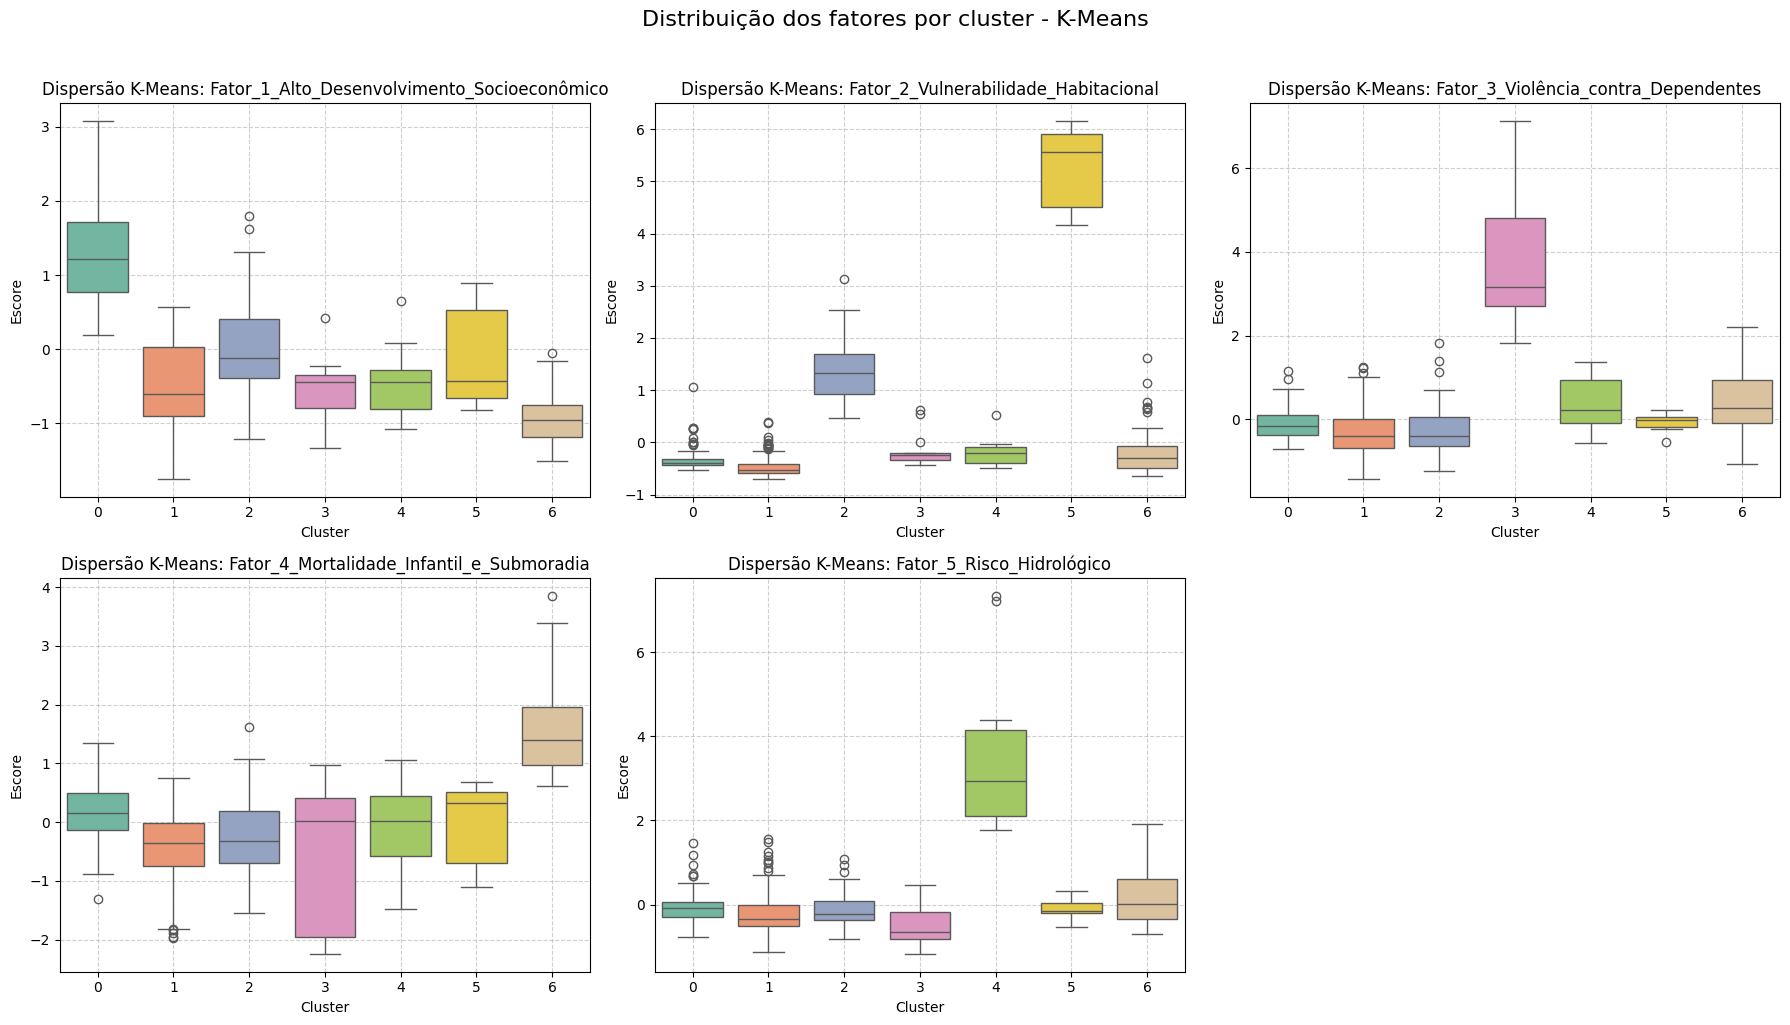

In [35]:
# Perfil dos clusters: escore fatorial médio de cada fator
centroides_kmeans = df_resultado.groupby("Cluster")[colunas_fatores].mean()

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    centroides_kmeans.T, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    cbar_kws={"label": "Escore fatorial médio"}, linewidths=0.5, linecolor="gray", ax=ax,
)
ax.set_title(f"Perfil tipológico: K-Means (K={k_definitivo})", fontsize=14, pad=15)
ax.set_xlabel("Clusters (K-Means)", fontsize=12)
ax.set_ylabel("Fatores latentes de qualidade de vida", fontsize=12)
plt.tight_layout()
plt.show()

# Distribuição dos escores de cada fator por cluster
n_colunas = 3
n_linhas = math.ceil(len(colunas_fatores) / n_colunas)
fig, axes = plt.subplots(n_linhas, n_colunas, figsize=(18, 5 * n_linhas))
paleta = sns.color_palette("Set2", k_definitivo)

for ax, fator in zip(axes.flat, colunas_fatores):
    sns.boxplot(data=df_resultado, x="Cluster", y=fator, hue="Cluster", palette=paleta, legend=False, ax=ax)
    ax.set_title(f"Dispersão K-Means: {fator}", fontsize=12)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Escore")
    ax.grid(True, linestyle="--", alpha=0.6)
for ax in list(axes.flat)[len(colunas_fatores):]:
    ax.axis("off")

plt.suptitle("Distribuição dos fatores por cluster - K-Means", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Exportação dos resultados

In [36]:
ARQUIVO_CLUSTERS = PASTA_RESULTADOS / "resultado_clusters.csv"
df_resultado.to_csv(ARQUIVO_CLUSTERS, sep=";", index=False, encoding="utf-8-sig")

print(f"{len(df_resultado)} registros exportados para {ARQUIVO_CLUSTERS.relative_to(RAIZ)}")
df_resultado.head()

384 registros exportados para data\results\resultado_clusters.csv


,Período,Distrito,Fator_1_Alto_Desenvolvimento_Socioeconômico,Fator_2_Vulnerabilidade_Habitacional,Fator_3_Violência_contra_Dependentes,Fator_4_Mortalidade_Infantil_e_Submoradia,Fator_5_Risco_Hidrológico,Cluster
0,2020,Alto de Pinheiros,2.330452,-0.324354,0.001272,0.428509,0.069868,0
1,2021,Alto de Pinheiros,2.568622,-0.317550,0.343661,1.084634,-0.083687,0
2,2022,Alto de Pinheiros,2.885625,-0.235941,0.732276,0.862467,0.072185,0
3,2023,Alto de Pinheiros,3.080818,-0.231109,0.585378,1.345562,0.188849,0
4,2020,Anhanguera,-1.747674,-0.698400,-1.345697,-1.090957,-0.504749,1


## Visualização dos clusters

Gera as figuras em `modeling&training/figures/clusters/` e a tabela em `data/results/`:

- `01_dispersao_fatores.png`: distritos-ano no plano PCA dos fatores, coloridos por cluster
- `02_perfil_clusters.png`: média de cada fator por cluster (use-a para nomear os clusters)
- `03_mapa_cluster_predominante.png`: mapa com o cluster mais frequente de cada distrito
- `04_mapa_por_ano.png`: um mapa por ano, pois os clusters são por distrito-ano
- `clusters_por_distrito.csv` (em `data/results/`): tabela distrito x ano com o cluster, o predominante e as trocas

In [37]:
# Nome de cada cluster. Use None ou omita o número para gerar o nome automático a partir dos
# dois fatores mais marcantes do centróide. A numeração do K-Means é arbitrária e pode mudar
# entre versões do scikit-learn: confira 02_perfil_clusters.png antes de nomear.
ROTULOS = {
    0: "Cluster 0",
    1: "Cluster 1",
    2: "Cluster 2",
    3: "Cluster 3",
    4: "Cluster 4",
    5: "Cluster 5",
    6: "Cluster 6",
}

NOMES_NO_MAPA_PREDOMINANTE = True
NOMES_NO_MAPA_POR_ANO = True
MOSTRAR_NUMERO_DO_CLUSTER = True  # escreve o número do cluster abaixo do nome do distrito
FONTE_NOME = 5.5                  # tamanho da fonte dos nomes no mapa predominante

# Malha dos 96 distritos (GeoSampa)
GEOJSON_URL = "https://raw.githubusercontent.com/codigourbano/distritos-sp/master/distritos-sp.geojson"
CAMPO_NOME_GEOJSON = "ds_nome"

COL_ANO, COL_DISTRITO, COL_CLUSTER = "Período", "Distrito", "Cluster"

# O número do cluster também é escrito no mapa, para que a leitura não dependa só da cor.
# As cores 7 e 8 só são usadas com mais de 6 clusters.
CORES = ["#184f95", "#eb6834", "#1baf7a", "#eda100", "#9085e9", "#6e6e6a", "#e34948", "#86b6ef"]

TINTA, TINTA_2, GRADE, FUNDO = "#1f1f1e", "#5f5e58", "#e4e3dd", "#fcfcfb"
HALO = [patheffects.withStroke(linewidth=1.8, foreground="white")]
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": TINTA,
    "axes.labelcolor": TINTA_2, "axes.edgecolor": GRADE, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "figure.facecolor": FUNDO, "axes.facecolor": FUNDO,
    "savefig.facecolor": FUNDO,
})


def normalizar(nome):
    """'São Miguel' -> 'SAO MIGUEL' (para casar com os nomes da malha)."""
    s = unicodedata.normalize("NFKD", str(nome)).encode("ascii", "ignore").decode()
    return " ".join(s.upper().replace("-", " ").split())


def selecionar_fatores(df):
    cols = [c for c in df.columns if c.startswith("Fator_")]
    if not cols:  # alternativa: qualquer coluna numérica que não seja identificador
        cols = [c for c in df.select_dtypes("number").columns if c not in (COL_ANO, COL_CLUSTER)]
    return cols


def nome_curto_fator(c):
    """'Fator_2_Vulnerabilidade_Habitacional' -> 'Vulnerabilidade Habitacional'."""
    partes = c.split("_")
    if len(partes) > 2 and partes[0] == "Fator":
        partes = partes[2:]
    return " ".join(partes)


def gerar_rotulos(df, fatores):
    perfil = df.groupby(COL_CLUSTER)[fatores].mean()
    rotulos = {}
    for c, linha in perfil.iterrows():
        manual = (ROTULOS or {}).get(int(c))
        if manual:
            rotulos[int(c)] = manual
            continue
        top = linha.abs().sort_values(ascending=False).index[:2]
        rotulos[int(c)] = " · ".join(f"{nome_curto_fator(f)} {'↑' if linha[f] > 0 else '↓'}" for f in top)
    return rotulos


def cor(c):
    return CORES[int(c) % len(CORES)]


def carregar_malha(geojson=None):
    """Retorna uma lista de {'nome', 'aneis'} com o anel externo de cada polígono dos distritos."""
    fonte = geojson or GEOJSON_URL
    if str(fonte).startswith("http"):
        print(f"Baixando malha dos distritos: {fonte}")
        with urllib.request.urlopen(fonte, timeout=60) as r:
            gj = json.loads(r.read().decode("utf-8"))
    else:
        gj = json.loads(Path(fonte).read_text(encoding="utf-8"))

    distritos = []
    for f in gj["features"]:
        g = f["geometry"]
        polis = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        aneis = [np.asarray(p[0])[:, :2] for p in polis]
        distritos.append({"nome": normalizar(f["properties"][CAMPO_NOME_GEOJSON]), "aneis": aneis})
    print(f"-> {len(distritos)} polígonos de distrito carregados")
    return distritos


def centroide(anel):
    x, y = anel[:, 0], anel[:, 1]
    a = x * np.roll(y, -1) - np.roll(x, -1) * y
    A = a.sum() / 2
    if abs(A) < 1e-12:
        return float(x.mean()), float(y.mean())
    return float(((x + np.roll(x, -1)) * a).sum() / (6 * A)), float(((y + np.roll(y, -1)) * a).sum() / (6 * A))


def area(anel):
    x, y = anel[:, 0], anel[:, 1]
    return abs((x * np.roll(y, -1) - np.roll(x, -1) * y).sum()) / 2


def quebrar(nome, largura=11):
    """Quebra nomes longos em até duas linhas ('Cidade Tiradentes' -> 'Cidade\\nTiradentes')."""
    if len(nome) <= largura or " " not in nome:
        return nome
    palavras, melhor = nome.split(), None
    for i in range(1, len(palavras)):
        a, b = " ".join(palavras[:i]), " ".join(palavras[i:])
        if melhor is None or max(len(a), len(b)) < max(map(len, melhor)):
            melhor = (a, b)
    return "\n".join(melhor)


def desenhar_mapa(ax, malha, cluster_por_distrito, destaque=frozenset(), numeros=True, fonte_num=6.5, nomes=None):
    patches, cores = [], []
    for d in malha:
        c = cluster_por_distrito.get(d["nome"])
        for anel in d["aneis"]:
            patches.append(Polygon(anel, closed=True))
            cores.append(cor(c) if c is not None else "#ffffff")
    ax.add_collection(PatchCollection(patches, facecolor=cores, edgecolor=FUNDO, linewidth=0.8))

    # Hachura nos distritos que trocaram de cluster entre os anos
    if destaque:
        hp = [Polygon(a, closed=True) for d in malha if d["nome"] in destaque for a in d["aneis"]]
        ax.add_collection(PatchCollection(hp, facecolor="none", edgecolor=TINTA, linewidth=0,
                                          hatch="////", alpha=0.35))

    for d in malha:
        c = cluster_por_distrito.get(d["nome"])
        if c is None or not (numeros or nomes):
            continue
        x, y = centroide(max(d["aneis"], key=area))
        if nomes:
            rotulo = quebrar(nomes.get(d["nome"], d["nome"].title()))
            if numeros:
                rotulo += f"\n{c}"
            ax.text(x, y, rotulo, ha="center", va="center", fontsize=fonte_num, color=TINTA,
                    linespacing=0.95, path_effects=HALO)
        else:
            ax.text(x, y, str(c), ha="center", va="center", fontsize=fonte_num, color="white",
                    fontweight="bold")

    todos = np.vstack([a for d in malha for a in d["aneis"]])
    ax.set_xlim(todos[:, 0].min() - 0.01, todos[:, 0].max() + 0.01)
    ax.set_ylim(todos[:, 1].min() - 0.01, todos[:, 1].max() + 0.01)
    ax.set_aspect(1 / math.cos(math.radians(todos[:, 1].mean())))  # evita distorção de longitude/latitude
    ax.axis("off")


def legenda_clusters(ax_ou_fig, clusters, rotulos, contagem=None, hachura=False, **kw):
    itens = []
    for c in clusters:
        txt = f"{c} — {rotulos.get(c, '')}"
        if contagem is not None:
            txt += f"  (n={contagem.get(c, 0)})"
        itens.append(Patch(facecolor=cor(c), edgecolor="none", label=txt))
    if hachura:
        itens.append(Patch(facecolor="white", edgecolor=TINTA, hatch="////", alpha=0.6,
                           label="Distrito mudou de cluster entre os anos"))
    return ax_ou_fig.legend(handles=itens, frameon=False, **kw)


def fig_dispersao(df, fatores, rotulos, saida):
    X = df[fatores].to_numpy()
    pca = PCA(n_components=2, random_state=42).fit(X)
    Z = pca.transform(X)
    var = pca.explained_variance_ratio_ * 100
    clusters = sorted(df[COL_CLUSTER].unique())

    fig, ax = plt.subplots(figsize=(11, 7.5))
    ax.grid(True, color=GRADE, linewidth=0.6)
    ax.set_axisbelow(True)
    for c in clusters:
        m = (df[COL_CLUSTER] == c).to_numpy()
        ax.scatter(Z[m, 0], Z[m, 1], s=36, color=cor(c), edgecolor=FUNDO, linewidth=1, alpha=0.9,
                   label=f"{c} — {rotulos[c]}  (n={m.sum()})")
        cx, cy = Z[m].mean(axis=0)
        ax.scatter(cx, cy, s=380, color=cor(c), edgecolor=TINTA, linewidth=1.5, zorder=5)
        ax.text(cx, cy, str(c), ha="center", va="center", color="white", fontweight="bold",
                fontsize=11, zorder=6)

    # Rotula apenas os 6 distritos-ano mais afastados do centro
    dist = np.linalg.norm(Z - Z.mean(axis=0), axis=1)
    for i in np.argsort(dist)[-6:]:
        ax.annotate(f"{df[COL_DISTRITO].iloc[i]} ({df[COL_ANO].iloc[i]})", Z[i], xytext=(6, 4),
                    textcoords="offset points", fontsize=8, color=TINTA_2)

    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.set_xlabel(f"Componente principal 1 ({var[0]:.1f}% da variância dos fatores)")
    ax.set_ylabel(f"Componente principal 2 ({var[1]:.1f}%)")
    ax.set_title("Distritos-ano no espaço dos fatores, por cluster", loc="left", fontsize=14,
                 fontweight="bold", pad=12)
    ax.legend(title="Cluster", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1),
              fontsize=9, title_fontsize=10, alignment="left")
    fig.tight_layout()
    fig.savefig(saida, dpi=200, bbox_inches="tight")
    plt.close(fig)


def fig_perfil(df, fatores, rotulos, saida):
    perfil = df.groupby(COL_CLUSTER)[fatores].mean()
    lim = np.ceil(np.abs(perfil.to_numpy()).max() * 10) / 10
    fig, ax = plt.subplots(figsize=(11, 0.75 * len(perfil) + 2.2))
    im = ax.imshow(perfil.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(fatores)), [nome_curto_fator(f).replace(" ", "\n") for f in fatores],
                  fontsize=9)
    ax.set_yticks(range(len(perfil)), [f"{c} — {rotulos[c]}" for c in perfil.index], fontsize=9)
    ax.xaxis.tick_top()
    for i in range(perfil.shape[0]):
        for j in range(perfil.shape[1]):
            v = perfil.iat[i, j]
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(v) > lim * 0.55 else TINTA)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cb.set_label("Média do escore fatorial (0 = média da cidade)")
    cb.outline.set_visible(False)
    ax.set_title(f"Perfil médio de cada cluster nos {len(fatores)} fatores", loc="left", fontsize=14,
                 fontweight="bold", pad=40)
    fig.tight_layout()
    fig.savefig(saida, dpi=200, bbox_inches="tight")
    plt.close(fig)


def tabela_distritos(df):
    wide = df.pivot_table(index=COL_DISTRITO, columns=COL_ANO, values=COL_CLUSTER, aggfunc="first")
    wide.columns = [f"Cluster_{a}" for a in wide.columns]
    anos = list(wide.columns)

    def moda(row):
        # Cluster predominante: o mais frequente; em empate, o do ano mais recente
        vc = row.dropna().astype(int).value_counts()
        empatados = set(vc[vc == vc.max()].index)
        for a in reversed(anos):
            if pd.notna(row[a]) and int(row[a]) in empatados:
                return int(row[a])

    wide["Cluster_predominante"] = wide[anos].apply(moda, axis=1)
    wide["N_clusters_distintos"] = wide[anos].nunique(axis=1)
    wide["Mudou_de_cluster"] = wide["N_clusters_distintos"] > 1
    return wide.reset_index()


def fig_mapa_predominante(tab, malha, rotulos, anos, saida):
    m = {normalizar(d): int(c) for d, c in zip(tab[COL_DISTRITO], tab["Cluster_predominante"])}
    mudou = {normalizar(d) for d, x in zip(tab[COL_DISTRITO], tab["Mudou_de_cluster"]) if x}
    cont = tab["Cluster_predominante"].value_counts().to_dict()

    nomes = {normalizar(d): d for d in tab[COL_DISTRITO]} if NOMES_NO_MAPA_PREDOMINANTE else None
    fig, ax = plt.subplots(figsize=(14, 18) if nomes else (10, 13))
    desenhar_mapa(ax, malha, m, destaque=mudou, numeros=MOSTRAR_NUMERO_DO_CLUSTER or not nomes,
                  fonte_num=FONTE_NOME if nomes else 7, nomes=nomes)
    periodo = f"{min(anos)}–{max(anos)}" if len(anos) > 1 else str(anos[0])
    ax.set_title(f"Cluster predominante por distrito — São Paulo, {periodo}", loc="left",
                 fontsize=15, fontweight="bold")
    legenda_clusters(ax, sorted(set(m.values())), rotulos, cont, hachura=bool(mudou),
                     loc="upper left", bbox_to_anchor=(0, 0), fontsize=9,
                     title="Cluster (n = nº de distritos)", title_fontsize=10, alignment="left")
    ax.text(0, -0.13 if nomes else -0.17, "Predominante = cluster mais frequente entre os anos (empate: ano mais "
            "recente). Malha: GeoSampa.", fontsize=8, color=TINTA_2, transform=ax.transAxes)
    fig.tight_layout()
    fig.savefig(saida, dpi=200, bbox_inches="tight")
    plt.close(fig)


def fig_mapas_por_ano(df, malha, rotulos, saida):
    anos = sorted(df[COL_ANO].unique())
    n = len(anos)
    ncol = min(n, 2 if n <= 4 else 3)
    nlin = math.ceil(n / ncol)
    nomes = {normalizar(d): d for d in df[COL_DISTRITO].unique()} if NOMES_NO_MAPA_POR_ANO else None
    esc = 1.45 if nomes else 1.0
    fig, axes = plt.subplots(nlin, ncol, figsize=(6.2 * ncol * esc, (8 * nlin) * esc + 1.2), squeeze=False)
    for ax, ano in zip(axes.flat, anos):
        d = df[df[COL_ANO] == ano]
        desenhar_mapa(ax, malha, {normalizar(a): int(c) for a, c in zip(d[COL_DISTRITO], d[COL_CLUSTER])},
                      numeros=MOSTRAR_NUMERO_DO_CLUSTER or not nomes,
                      fonte_num=FONTE_NOME * 0.85 if nomes else 5.5, nomes=nomes)
        ax.set_title(str(ano), loc="left", fontsize=13, fontweight="bold")
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    clusters = sorted(df[COL_CLUSTER].unique())
    legenda_clusters(fig, clusters, rotulos, loc="lower center", ncol=min(3, len(clusters)),
                     bbox_to_anchor=(0.5, 0), fontsize=9)
    fig.suptitle("Cluster de cada distrito, por ano", x=0.02, ha="left", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=(0, 0.06, 1, 0.97))
    fig.savefig(saida, dpi=200, bbox_inches="tight")
    plt.close(fig)


def fig_evolucao_distritos(df, rotulos, saida):
    ct = (
        pd.crosstab(df[COL_ANO], df[COL_CLUSTER])
        .reindex(columns=sorted(rotulos), fill_value=0)
    )
    fig, ax = plt.subplots(figsize=(8, 3.3))
    base = np.zeros(len(ct))
    for c in ct.columns:
        valores = ct[c].to_numpy()
        ax.barh(ct.index.astype(str), valores, left=base, color=cor(c), edgecolor=FUNDO, linewidth=1,
                label=f"{c} — {rotulos[c]}")
        for i, (inicio, v) in enumerate(zip(base, valores)):
            if v >= 3:  # barras estreitas ficam sem rótulo
                ax.text(inicio + v / 2, i, str(int(v)), ha="center", va="center", color="white",
                        fontsize=8.5, fontweight="bold")
        base += valores

    ax.invert_yaxis()
    ax.set_xlim(0, df[COL_DISTRITO].nunique())
    ax.set_xlabel("Nº de distritos")
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.legend(ncol=2, fontsize=7.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25))
    fig.tight_layout()
    fig.savefig(saida, dpi=200, bbox_inches="tight")
    plt.close(fig)


def fig_evolucao_fatores(df, fatores, saida):
    medias = df.groupby(COL_ANO)[fatores].mean()
    fig, ax = plt.subplots(figsize=(6.5, 3))
    for i, fator in enumerate(fatores):
        ax.plot(medias.index, medias[fator], "o-", color=cor(i), linewidth=2,
                label=f"F{i + 1} {nome_curto_fator(fator)}")
    ax.axhline(0, color=GRADE, linewidth=1)
    ax.set_xticks(medias.index)
    ax.set_ylabel("Média da cidade")
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.legend(fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.tight_layout()
    fig.savefig(saida, dpi=200, bbox_inches="tight")
    plt.close(fig)


def gerar_tudo(df, pasta_saida, pasta_tabela=None, geojson=None, mostrar=False):
    """Gera as figuras em `pasta_saida` e a tabela por distrito em `pasta_tabela` (padrão: `pasta_saida`)."""
    df = df.copy()
    df[COL_CLUSTER] = df[COL_CLUSTER].astype(int)
    fatores = selecionar_fatores(df)
    rotulos = gerar_rotulos(df, fatores)
    out = Path(pasta_saida)
    out.mkdir(parents=True, exist_ok=True)
    out_tab = Path(pasta_tabela) if pasta_tabela else out
    out_tab.mkdir(parents=True, exist_ok=True)

    malha = carregar_malha(geojson)
    nomes_malha = {d["nome"] for d in malha}
    sem_mapa = sorted({d for d in df[COL_DISTRITO].unique() if normalizar(d) not in nomes_malha})
    if sem_mapa:
        print(f"AVISO: {len(sem_mapa)} distrito(s) sem polígono correspondente: {sem_mapa}")
    else:
        print(f"-> todos os {df[COL_DISTRITO].nunique()} distritos casaram com a malha")

    print("Clusters:")
    for c, r in rotulos.items():
        print(f"   {c}: {r}")

    tab = tabela_distritos(df)
    tab.to_csv(out_tab / "clusters_por_distrito.csv", sep=";", index=False, encoding="utf-8-sig")

    figs = [
        ("01_dispersao_fatores.png", lambda p: fig_dispersao(df, fatores, rotulos, p)),
        ("02_perfil_clusters.png", lambda p: fig_perfil(df, fatores, rotulos, p)),
        ("03_mapa_cluster_predominante.png",
         lambda p: fig_mapa_predominante(tab, malha, rotulos, sorted(df[COL_ANO].unique()), p)),
        ("04_mapa_por_ano.png", lambda p: fig_mapas_por_ano(df, malha, rotulos, p)),
        ("05_evolucao_distritos_por_cluster.png", lambda p: fig_evolucao_distritos(df, rotulos, p)),
        ("06_evolucao_fatores_por_ano.png", lambda p: fig_evolucao_fatores(df, fatores, p)),
    ]
    for nome, f in figs:
        f(out / nome)
        print(f"-> {out / nome}")
    print(f"-> {out_tab / 'clusters_por_distrito.csv'}  "
          f"({int(tab['Mudou_de_cluster'].sum())} distritos mudaram de cluster entre os anos)")

    if mostrar:
        from IPython.display import Image, display
        for nome, _ in figs:
            display(Image(filename=str(out / nome)))
    return tab

Baixando malha dos distritos: https://raw.githubusercontent.com/codigourbano/distritos-sp/master/distritos-sp.geojson
-> 96 polígonos de distrito carregados
-> todos os 96 distritos casaram com a malha
Clusters:
   0: Cluster 0
   1: Cluster 1
   2: Cluster 2
   3: Cluster 3
   4: Cluster 4
   5: Cluster 5
   6: Cluster 6
-> c:\Users\tenor\QoLsterizer\modeling&training\figures\clusters\01_dispersao_fatores.png
-> c:\Users\tenor\QoLsterizer\modeling&training\figures\clusters\02_perfil_clusters.png
-> c:\Users\tenor\QoLsterizer\modeling&training\figures\clusters\03_mapa_cluster_predominante.png
-> c:\Users\tenor\QoLsterizer\modeling&training\figures\clusters\04_mapa_por_ano.png
-> c:\Users\tenor\QoLsterizer\modeling&training\figures\clusters\05_evolucao_distritos_por_cluster.png
-> c:\Users\tenor\QoLsterizer\modeling&training\figures\clusters\06_evolucao_fatores_por_ano.png
-> c:\Users\tenor\QoLsterizer\data\results\clusters_por_distrito.csv  (36 distritos mudaram de cluster entre os ano

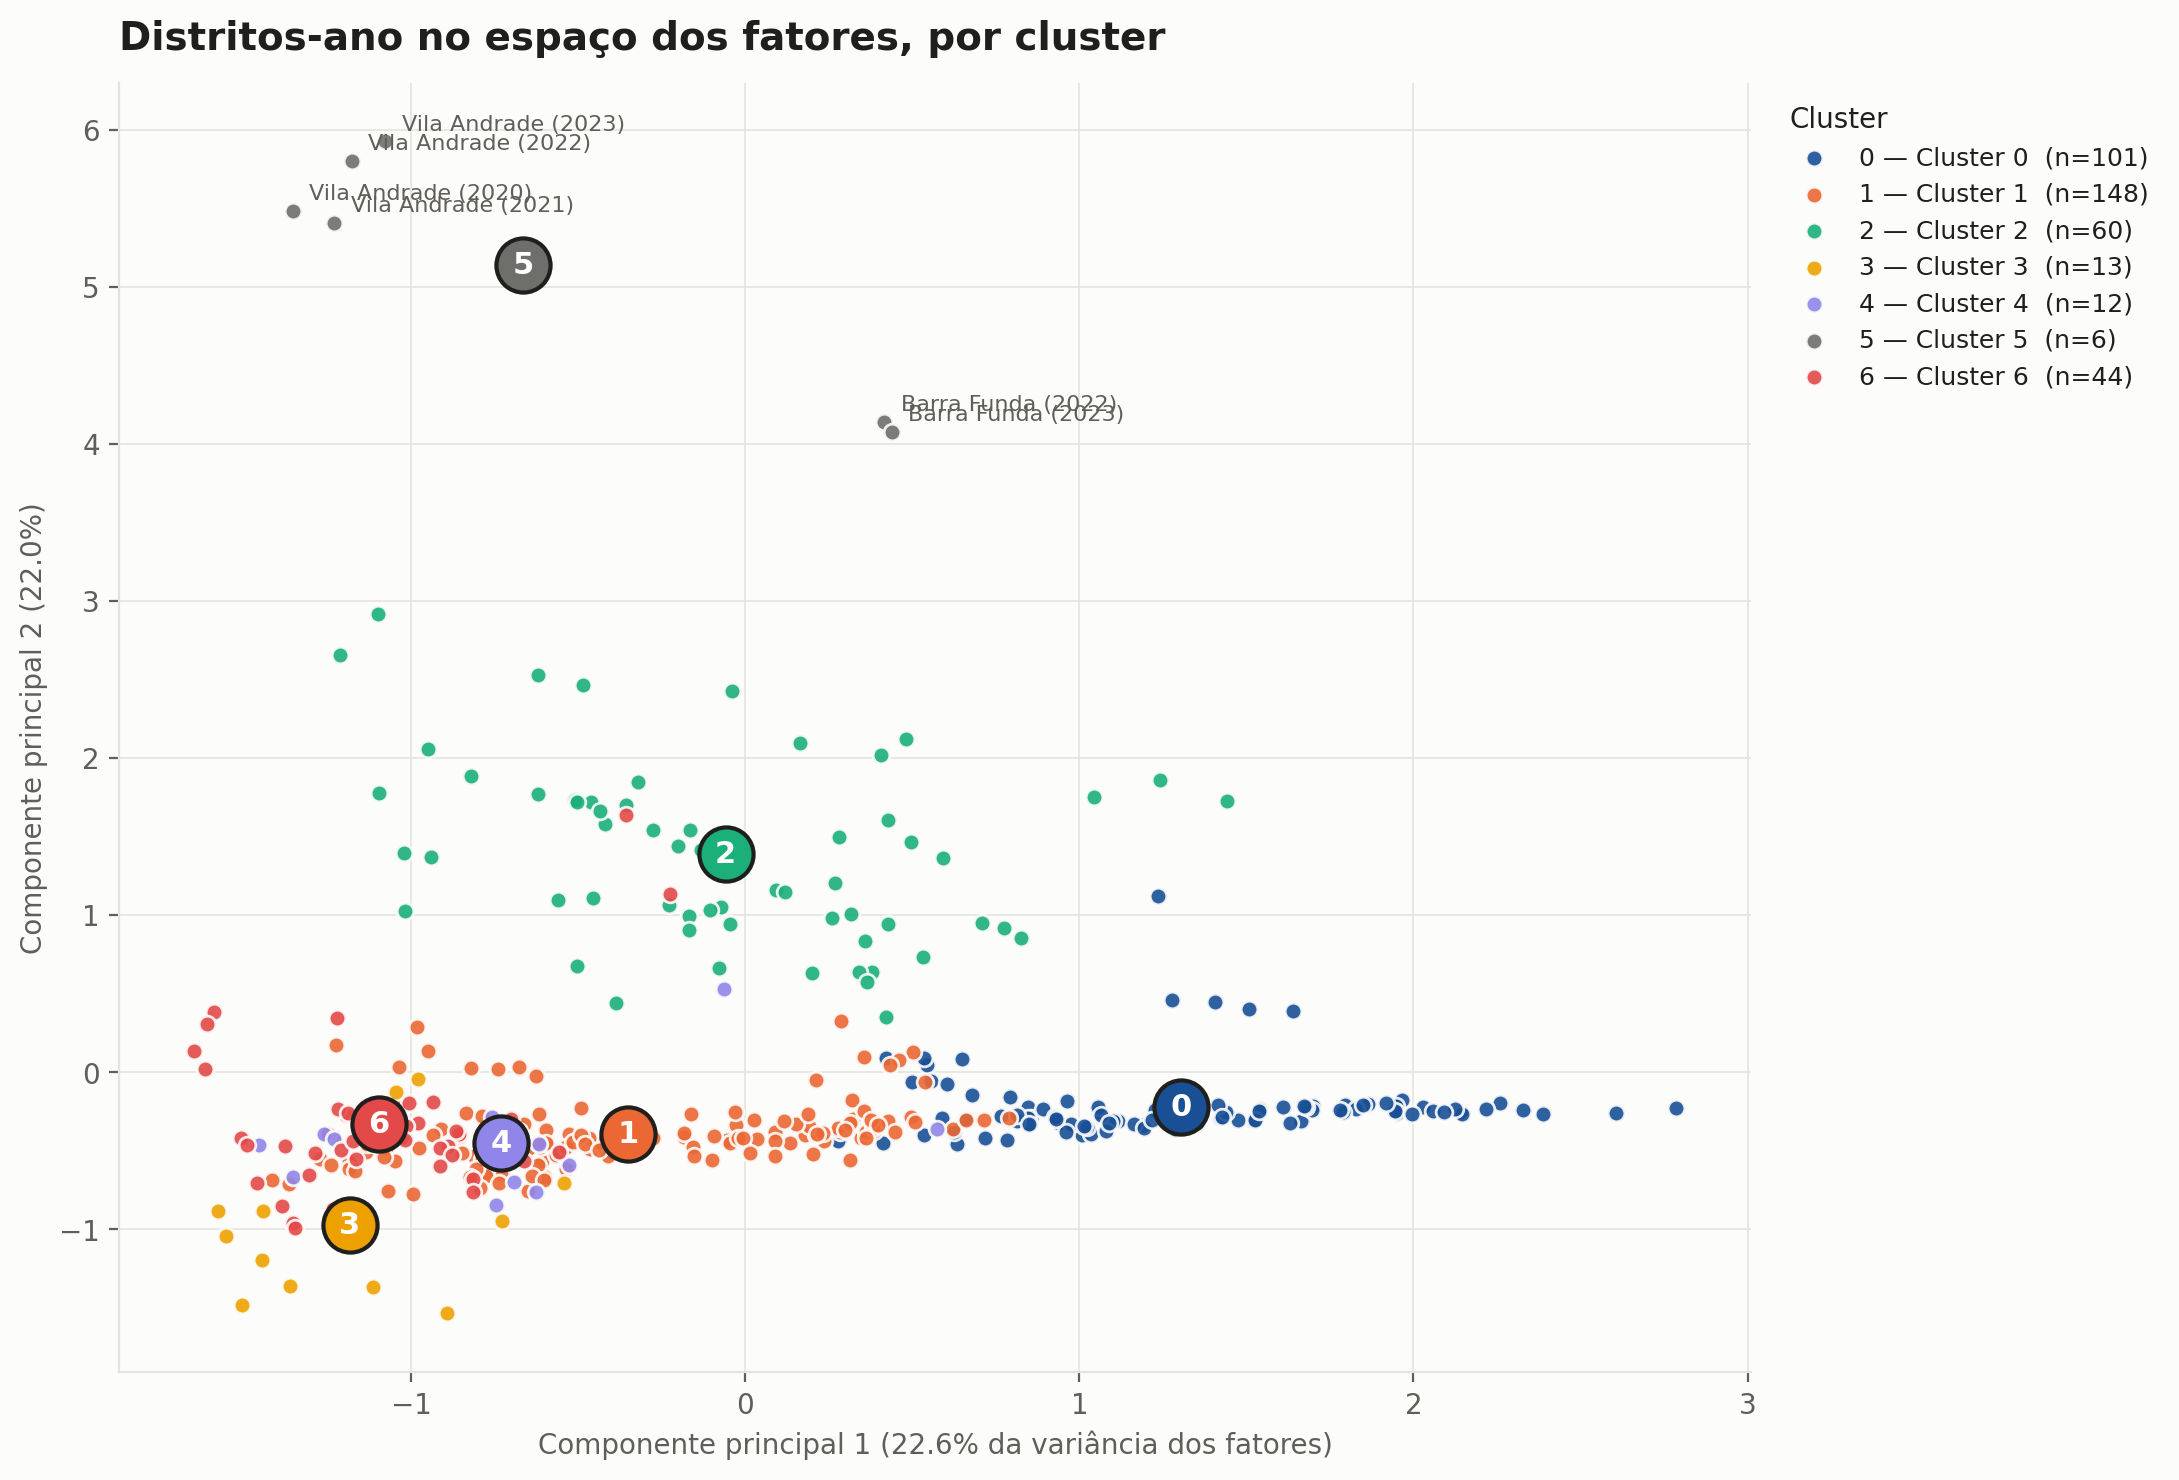

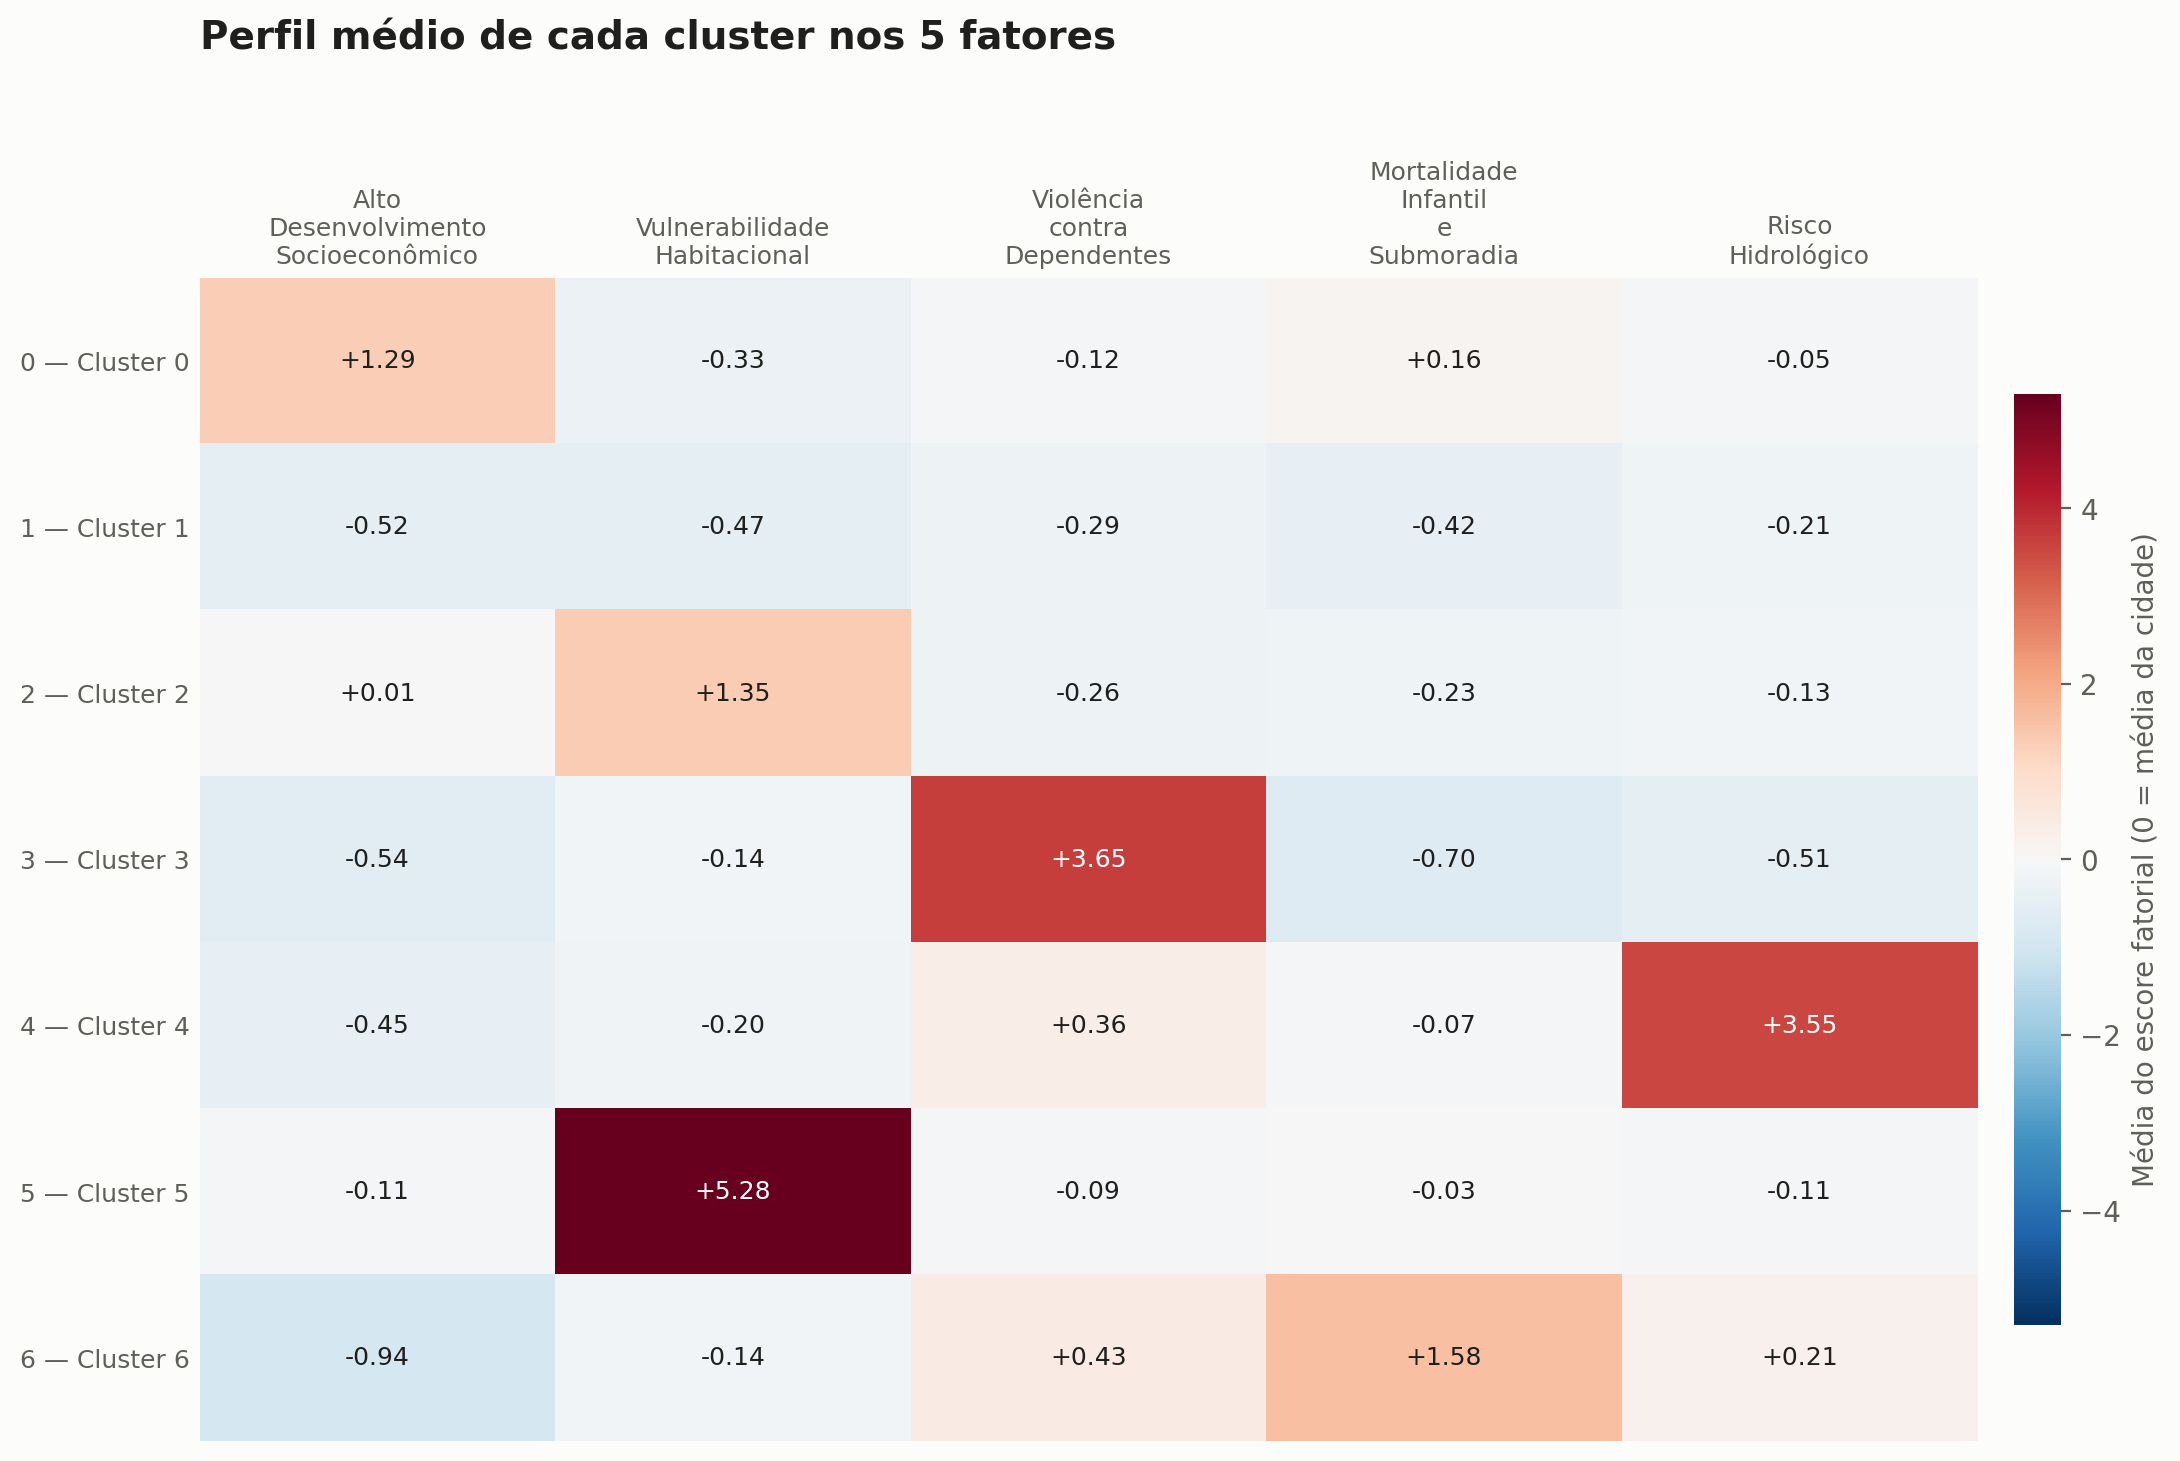

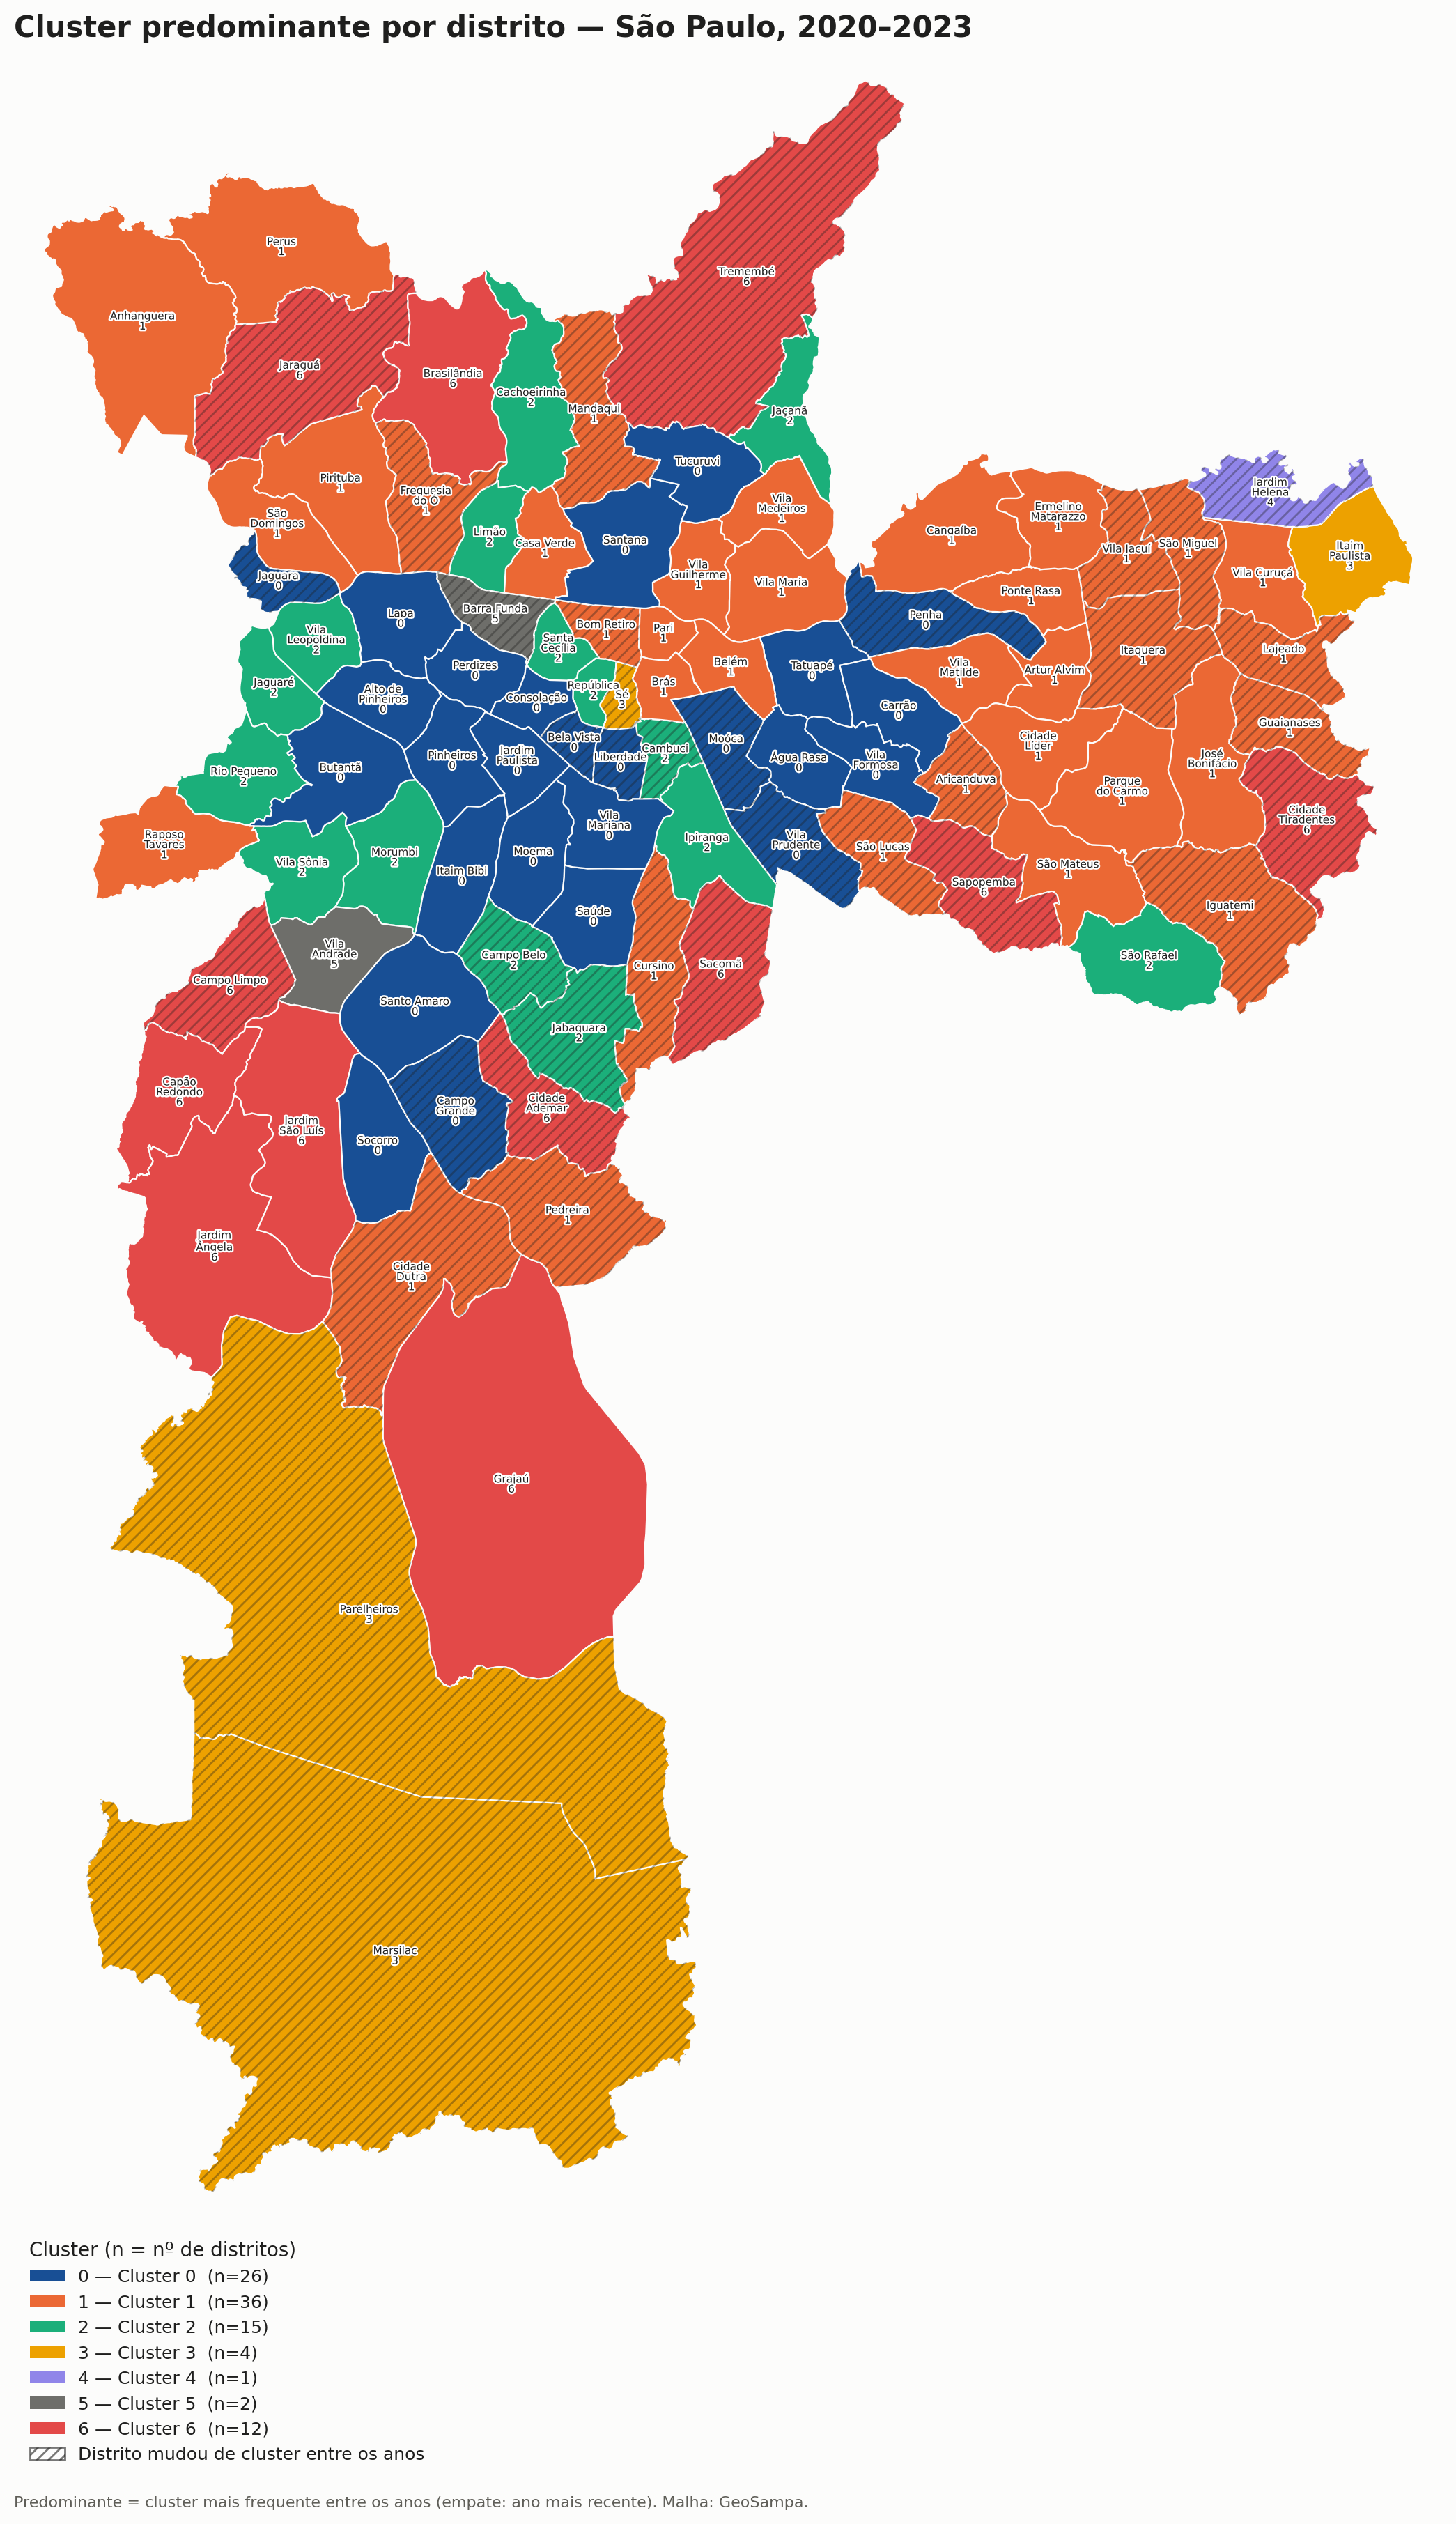

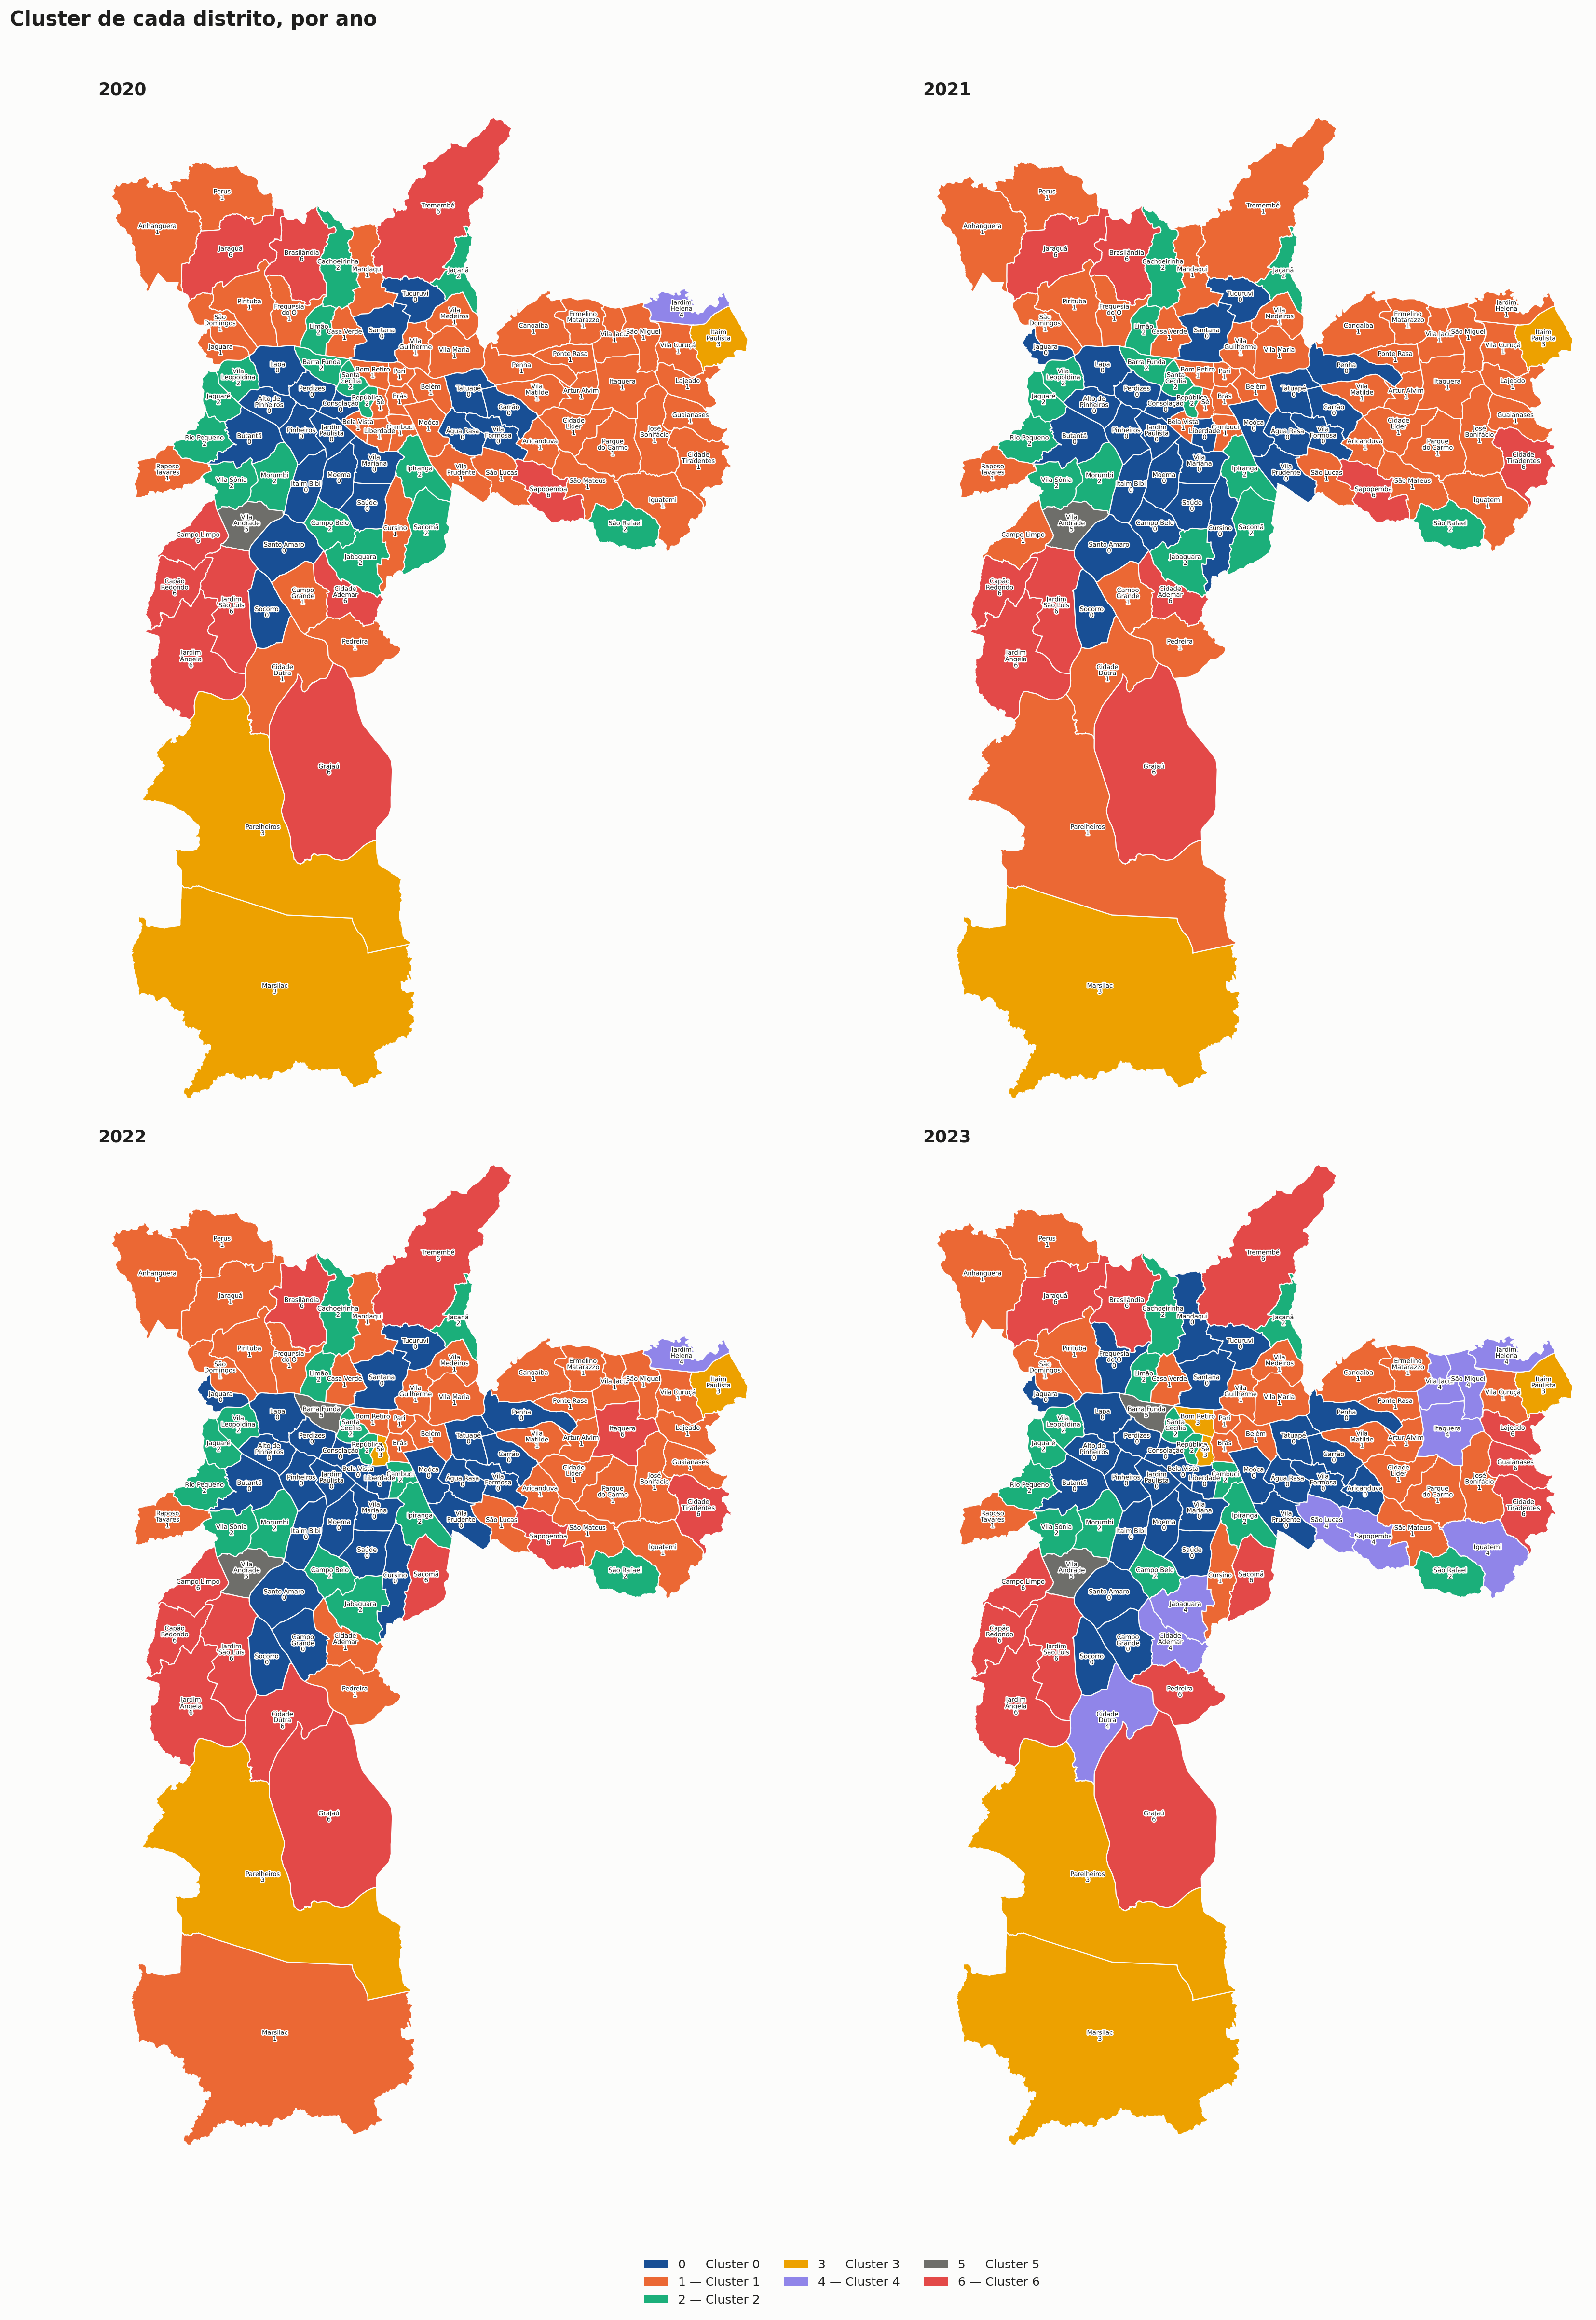

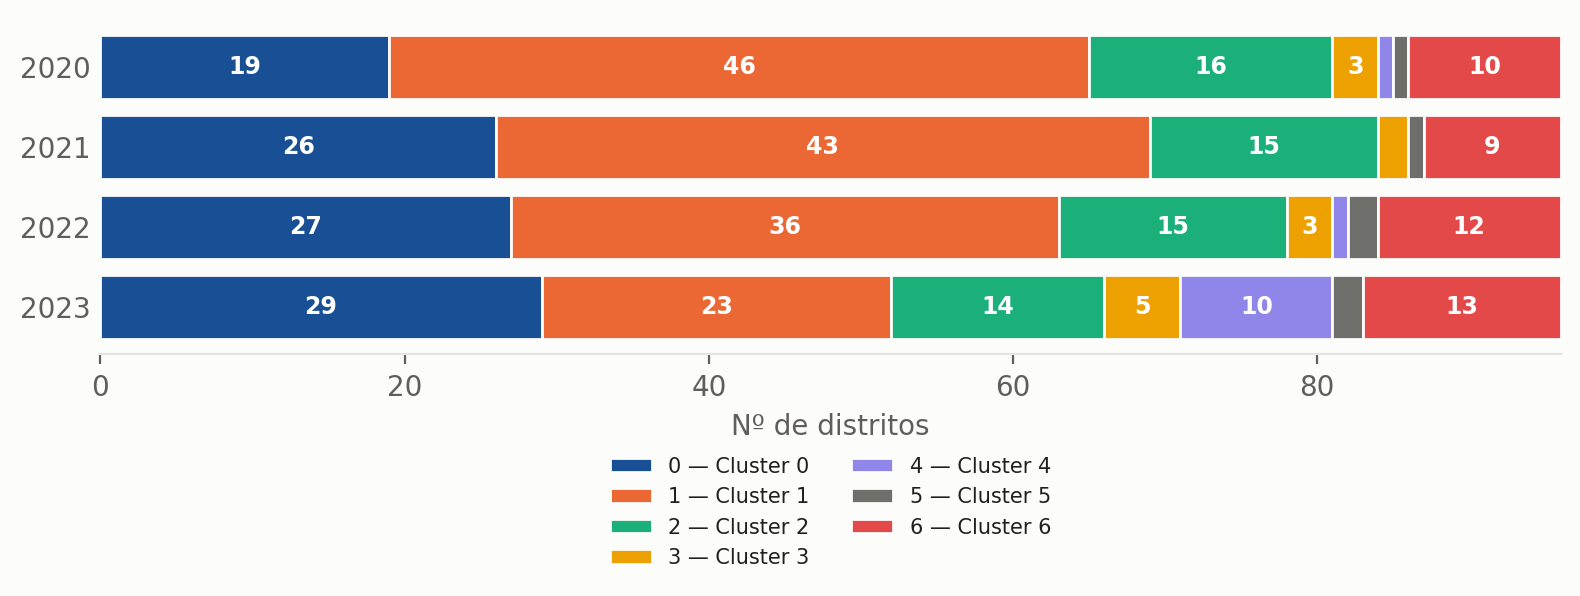

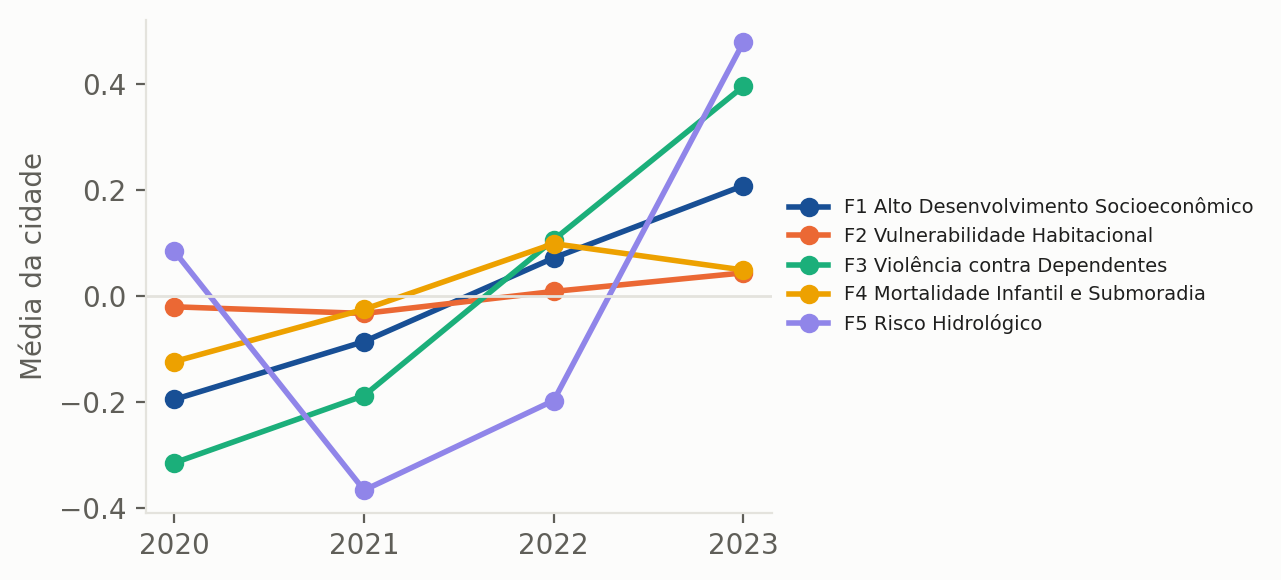

In [38]:
# A malha dos distritos é baixada do GitHub; para usar um arquivo local, passe geojson="caminho.geojson"
tabela_clusters = gerar_tudo(
    df_resultado, pasta_saida=PASTA_FIGURAS / "clusters", pasta_tabela=PASTA_RESULTADOS, mostrar=True
)